# Exploratory Data Analysis (EDA) & Perbandingan Model Machine Learning Clustering — CekGarasi

**Proyek:** CekGarasi — Platform Business Intelligence & Rekomendasi Segmentasi Pasar Mobil Bekas  
**Tujuan Notebook:**  
1. Mendokumentasikan alur **awal pembuatan model Machine Learning K-Means** pada platform CekGarasi mulai dari eksplorasi data mentah hingga deployment.
2. Menyajikan **perbandingan objektif dan kuantitatif** antara algoritma **K-Means** dengan berbagai algoritma *unsupervised clustering* lainnya (**Agglomerative Hierarchical Clustering**, **Gaussian Mixture Model / GMM**, **Bisecting K-Means**, **MiniBatch K-Means**, **Spectral Clustering**, dan **DBSCAN**).
3. Menjelaskan **alasan ilmiah & bisnis mengapa K-Means ($K=3$) dipilih** sebagai model utama di produksi.

---

### Urutan Tahapan Analisis:
1. **1. Exploratory Data Analysis (EDA):** Inspeksi skema dataset, statistik deskriptif, deteksi *missing values* & duplikat, deteksi *outlier* ekstrem, distribusi univariat, komposisi kategorikal, dan matriks korelasi antar fitur.
2. **2. Preprocessing Data:** Seleksi 4 fitur numerik utama (`tahun`, `jarak_tempuh_ribu_km`, `harga_rp`, `total_fitur`), penyaringan anomali jarak tempuh (> 1.000 ribu km), dan pembuktian efek standardisasi *Z-Score* (`StandardScaler` vs `MinMaxScaler` vs Tanpa Scaling).
3. **3. Modelling:** Eksperimen penentuan jumlah klaster optimal ($K \in [2..10]$) dengan *Elbow Method* & *Silhouette Analysis*, diikuti pelatihan 7 variasi model *clustering* pada matriks fitur terstandardisasi yang sama.
4. **4. Evaluasi Model & Alasan Pemilihan K-Means:** Evaluasi komparatif menggunakan **Silhouette Score**, **Davies-Bouldin Index (DBI)**, **Calinski-Harabasz Index (CHI)**, **Stabilitas 30-Run Bootstrap (ARI)**, waktu komputasi, visualisasi proyeksi **PCA 2D**, serta interpretasi bisnis 3 segmen pasar CekGarasi.

## 1. Exploratory Data Analysis (EDA)

Tahap pertama adalah memuat dataset katalog mobil bekas dari basis data produksi (`backend/data/cekgarasi.db`) dan memeriksa struktur tabel, tipe data, sebaran nilai, serta potensi anomali sebelum masuk ke tahap pra-pemrosesan.

In [1]:
import os
import time
import warnings
import sqlite3
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.cluster import (
    KMeans,
    MiniBatchKMeans,
    BisectingKMeans,
    AgglomerativeClustering,
    SpectralClustering,
    DBSCAN,
)
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
)
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 10

# Lokasi file database dan artefak produksi CekGarasi
WORKSPACE_DIR = r"h:\cekgarasi-20261105T071525Z-1-001\cekgarasi"
DB_PATH = os.path.join(WORKSPACE_DIR, "backend", "data", "cekgarasi.db")
SCALER_PATH = os.path.join(WORKSPACE_DIR, "backend", "artifacts", "scaler_mobil.pkl")
MODEL_PATH = os.path.join(WORKSPACE_DIR, "backend", "artifacts", "model_kmeans.pkl")

conn = sqlite3.connect(DB_PATH)
query = '''
SELECT 
    c.id,
    c.nama_mobil,
    b.nama AS merek,
    m.nama AS model,
    m.tipe_bodi,
    c.tahun,
    c.jarak_tempuh_ribu_km,
    c.transmisi,
    c.harga_rp,
    c.total_fitur,
    c.klaster AS klaster_produksi,
    s.nama_pendek AS segmen_produksi
FROM cars c
LEFT JOIN car_models m ON c.model_id = m.id
LEFT JOIN brands b ON m.brand_id = b.id
LEFT JOIN segments s ON c.klaster = s.id
ORDER BY c.id
'''
df_raw = pd.read_sql_query(query, conn)
conn.close()

print(f"Total baris dataset mentah : {df_raw.shape[0]} unit mobil")
print(f"Total kolom atribut        : {df_raw.shape[1]} kolom")
print("\n--- Tipe Data & Informasi Kolom ---")
print(df_raw.dtypes)
print("\n--- 5 Sampel Data Pertama ---")
print(df_raw.head().to_string(index=False))

Total baris dataset mentah : 610 unit mobil
Total kolom atribut        : 12 kolom

--- Tipe Data & Informasi Kolom ---
id                        int64
nama_mobil                  str
merek                       str
model                       str
tipe_bodi                   str
tahun                     int64
jarak_tempuh_ribu_km    float64
transmisi                   str
harga_rp                  int64
total_fitur               int64
klaster_produksi          int64
segmen_produksi             str
dtype: object

--- 5 Sampel Data Pertama ---
 id            nama_mobil    merek   model tipe_bodi  tahun  jarak_tempuh_ribu_km transmisi  harga_rp  total_fitur  klaster_produksi segmen_produksi
  1            AYLA X 1.2 Daihatsu    AYLA Hatchback   2018                10.508    Manual 101000000            0                 1   Keluarga Muda
  2 AGYA TRD SPORTIVO 1.0   Toyota    AGYA Hatchback   2015               112.888    Manual  82000000            0                 2        Ekonomis
  3  

### Analisis Struktur Dataset Mentah
- Dataset mentah terdiri dari **610 unit mobil bekas** dengan **12 atribut** yang mencakup identitas kendaraan (`id`, `nama_mobil`, `merek`, `model`, `tipe_bodi`), karakteristik teknis & usia (`tahun`, `jarak_tempuh_ribu_km`, `transmisi`, `total_fitur`), nilai ekonomi (`harga_rp`), serta label segmen produksi (`klaster_produksi`, `segmen_produksi`).
- Selanjutnya, kita melakukan pemeriksaan kualitas data: mengecek apakah terdapat **missing values (nilai kosong)**, **data duplikat**, serta melihat **statistik deskriptif** (mean, standar deviasi, kuartil, minimum, dan maksimum).

In [2]:
FITUR_NUMERIK = ["tahun", "jarak_tempuh_ribu_km", "harga_rp", "total_fitur"]

print("=== 1. Pengecekan Missing Values (Nilai Kosong) ===")
print(df_raw.isnull().sum())

print(f"\n=== 2. Pengecekan Baris Duplikat (berdasarkan ID): {df_raw['id'].duplicated().sum()} baris ===")

print("\n=== 3. Statistik Deskriptif Fitur Numerik (Sebelum Penyaringan Outlier) ===")
desc_raw = df_raw[FITUR_NUMERIK].describe().T
desc_raw["iqr"] = desc_raw["75%"] - desc_raw["25%"]
desc_raw["skewness"] = df_raw[FITUR_NUMERIK].skew()
print(desc_raw[["count", "mean", "std", "min", "25%", "50%", "75%", "max", "iqr", "skewness"]].round(2).to_string())

=== 1. Pengecekan Missing Values (Nilai Kosong) ===
id                      0
nama_mobil              0
merek                   0
model                   0
tipe_bodi               0
tahun                   0
jarak_tempuh_ribu_km    0
transmisi               0
harga_rp                0
total_fitur             0
klaster_produksi        0
segmen_produksi         0
dtype: int64

=== 2. Pengecekan Baris Duplikat (berdasarkan ID): 0 baris ===

=== 3. Statistik Deskriptif Fitur Numerik (Sebelum Penyaringan Outlier) ===
                      count          mean          std          min           25%           50%           75%          max          iqr  skewness
tahun                 610.0  2.018060e+03         2.03      2010.00  2.017000e+03  2.018000e+03  2.019000e+03       2023.0         2.00     -0.59
jarak_tempuh_ribu_km  610.0  1.613800e+02      2479.69         0.18  3.901000e+01  5.831000e+01  8.124000e+01      61300.0        42.24     24.69
harga_rp              610.0  1.828336e+08  6

### Temuan Kritis pada Statistik Deskriptif Awal
1. **Kelengkapan Data (Zero Missing Values):** Tidak ditemukan nilai kosong (`0` *missing values*) maupun duplikasi ID pada ke-610 baris data.
2. **Deteksi Anomali/Outlier Ekstrem pada `jarak_tempuh_ribu_km`:**
   - Kuartil ke-3 (`75%`) jarak tempuh berada di angka **80,68 ribu km**, namun nilai maksimum (`max`) melonjak drastis hingga **61.404,97 ribu km (61,4 juta km)** dengan *skewness* mencapai **24,69**!
   - Secara domain otomotif, angka 61,4 juta km tidak mungkin dicapai oleh mobil penumpang dan merupakan kesalahan input data (*human error* saat pencatatan satuan kilometer vs ribu kilometer).
   - Mari kita inspeksi baris anomali tersebut dan visualisasikan distribusi fitur sebelum dan sesudah pembersihan *outlier*.

=== Unit Mobil dengan Anomali Jarak Tempuh (> 1.000 Ribu KM) ===
 id   nama_mobil  tahun  jarak_tempuh_ribu_km  harga_rp  total_fitur
610 Xenia Kalcer   2022               61300.0  95000000            2


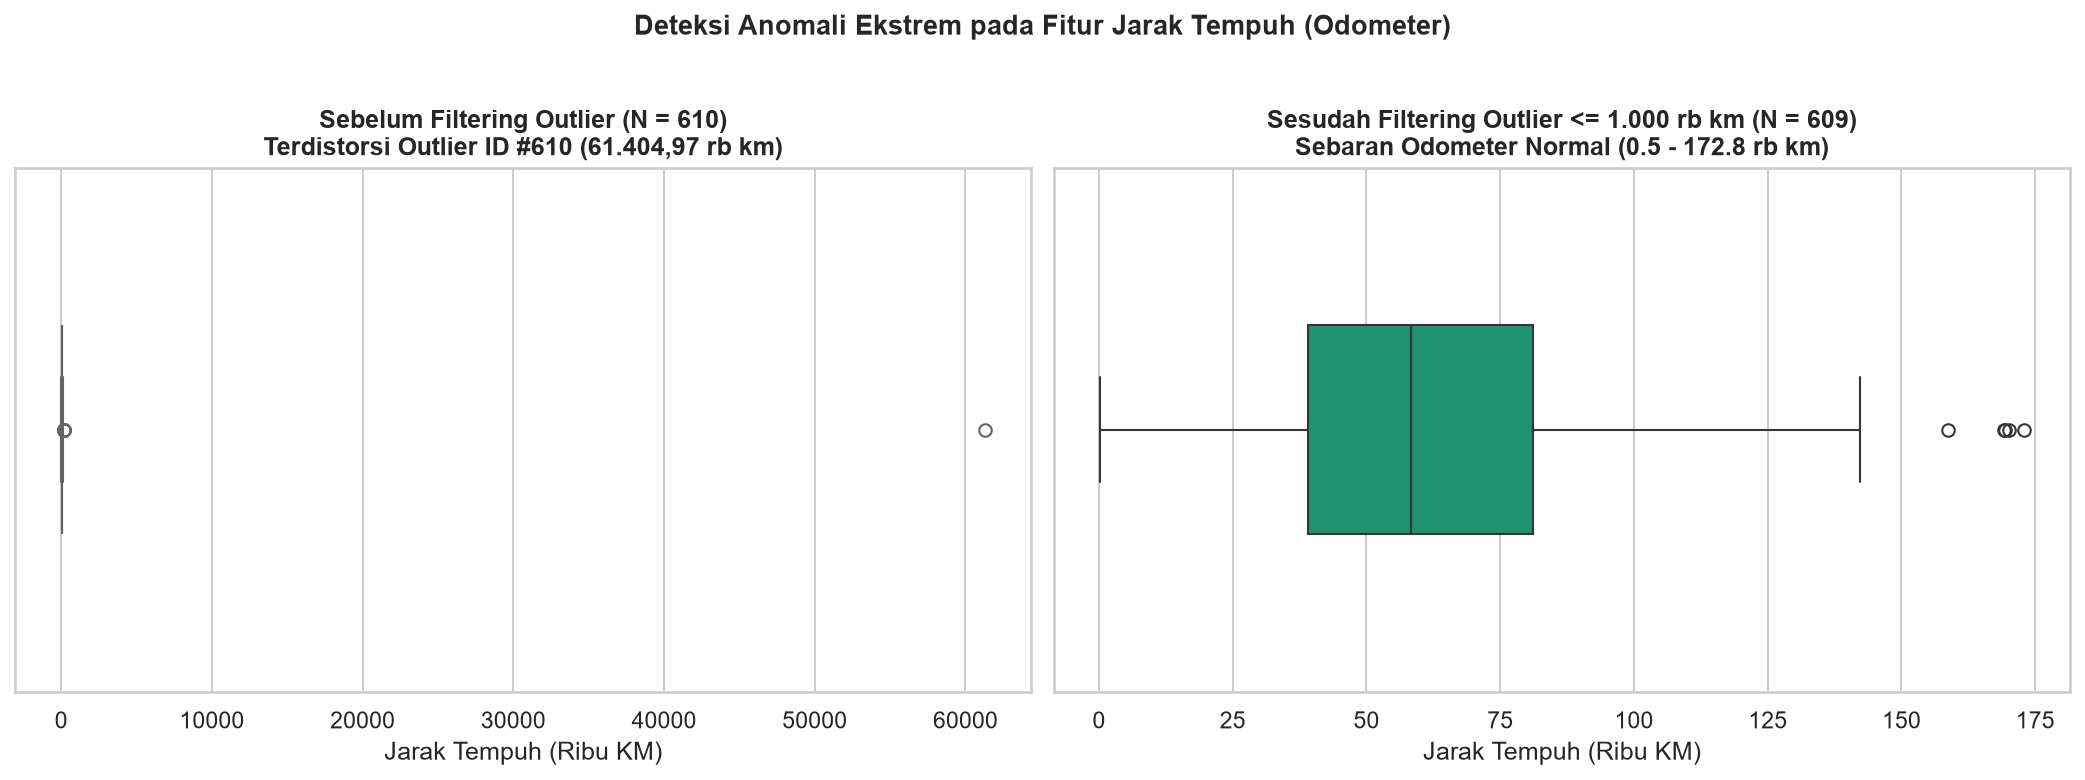

In [3]:
# Deteksi unit dengan jarak tempuh tidak wajar (> 1.000 ribu km atau 1 juta km)
BATAS_KM_WAJAR = 1000.0
outliers_km = df_raw[df_raw["jarak_tempuh_ribu_km"] > BATAS_KM_WAJAR]
print("=== Unit Mobil dengan Anomali Jarak Tempuh (> 1.000 Ribu KM) ===")
print(outliers_km[["id", "nama_mobil", "tahun", "jarak_tempuh_ribu_km", "harga_rp", "total_fitur"]].to_string(index=False))

# Visualisasi Boxplot Sebelum vs Sesudah Penyaringan Anomali Odometer
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(x=df_raw["jarak_tempuh_ribu_km"], ax=axes[0], color="#FA5252", width=0.4)
axes[0].set_title("Sebelum Filtering Outlier (N = 610)\nTerdistorsi Outlier ID #610 (61.404,97 rb km)", fontweight="bold")
axes[0].set_xlabel("Jarak Tempuh (Ribu KM)")

df_clean_preview = df_raw[df_raw["jarak_tempuh_ribu_km"] <= BATAS_KM_WAJAR]
sns.boxplot(x=df_clean_preview["jarak_tempuh_ribu_km"], ax=axes[1], color="#0CA678", width=0.4)
axes[1].set_title("Sesudah Filtering Outlier <= 1.000 rb km (N = 609)\nSebaran Odometer Normal (0.5 - 172.8 rb km)", fontweight="bold")
axes[1].set_xlabel("Jarak Tempuh (Ribu KM)")

plt.suptitle("Deteksi Anomali Ekstrem pada Fitur Jarak Tempuh (Odometer)", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

### Analisis Outlier Odometer & Distribusi 4 Fitur Utama
- Unit dengan `id = 610` tercatat memiliki odometer `61.404,97 ribu km` (61,4 juta km). Jika unit ini tidak disaring, rata-rata (*mean*) dan standar deviasi fitur jarak tempuh akan rusak parah, sehingga menarik pusat klaster (*centroid*) menjauhi populasi sebenarnya.
- Setelah menyaring 1 unit tidak wajar tersebut, tersisa **609 unit mobil valid** dengan rentang odometer wajar antara **0,50 ribu km hingga 172,80 ribu km** (rata-rata **60,99 ribu km**, median **58,28 ribu km**).
- Berikut adalah visualisasi distribusi univariat (Histogram + KDE) untuk keempat fitur numerik utama pada 609 unit mobil valid.

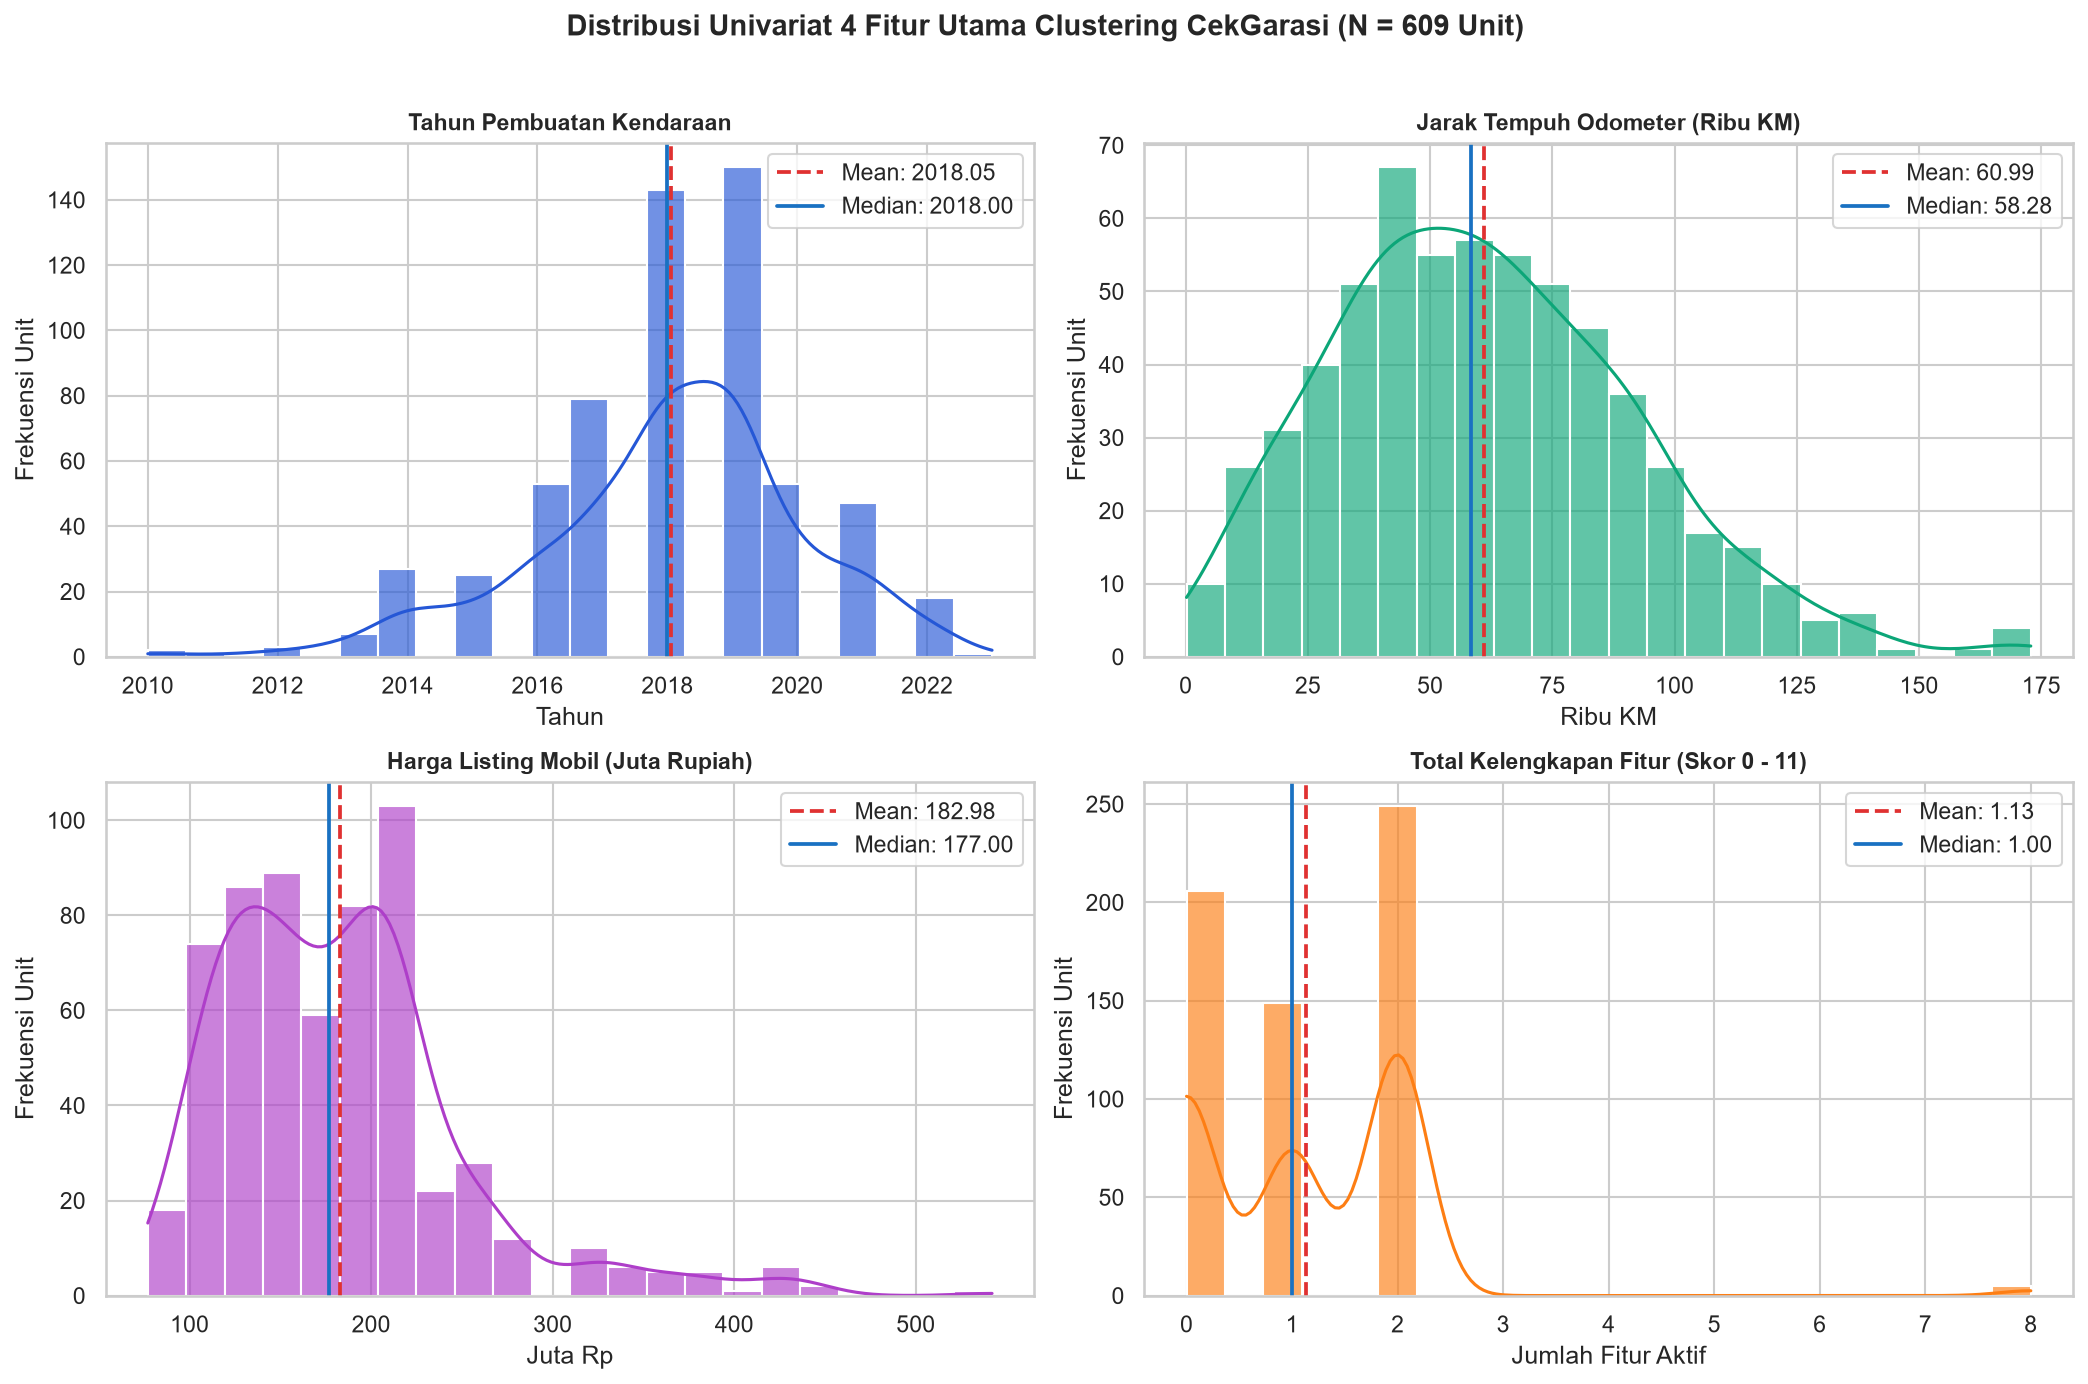

In [4]:
df_eda = df_raw[df_raw["jarak_tempuh_ribu_km"] <= BATAS_KM_WAJAR].copy().reset_index(drop=True)
df_eda["harga_juta"] = df_eda["harga_rp"] / 1e6

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fitur_plot = [
    ("tahun", "Tahun Pembuatan Kendaraan", "#2557D6", "Tahun"),
    ("jarak_tempuh_ribu_km", "Jarak Tempuh Odometer (Ribu KM)", "#0CA678", "Ribu KM"),
    ("harga_juta", "Harga Listing Mobil (Juta Rupiah)", "#AE3EC9", "Juta Rp"),
    ("total_fitur", "Total Kelengkapan Fitur (Skor 0 - 11)", "#FD7E14", "Jumlah Fitur Aktif"),
]

for ax, (col, title, color, xlabel) in zip(axes.flat, fitur_plot):
    sns.histplot(df_eda[col], kde=True, ax=ax, color=color, bins=22, alpha=0.65, edgecolor="white")
    mean_val = df_eda[col].mean()
    med_val = df_eda[col].median()
    ax.axvline(mean_val, color="#E03131", linestyle="--", linewidth=1.8, label=f"Mean: {mean_val:.2f}")
    ax.axvline(med_val, color="#1971C2", linestyle="-", linewidth=1.8, label=f"Median: {med_val:.2f}")
    ax.set_title(title, fontweight="bold", fontsize=11)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Frekuensi Unit")
    ax.legend(loc="upper right", frameon=True)

plt.suptitle("Distribusi Univariat 4 Fitur Utama Clustering CekGarasi (N = 609 Unit)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

### Interpretasi Distribusi Fitur Numerik
1. **Tahun Pembuatan (`tahun`):** Berdistribusi miring ke kiri (*left-skewed*, rentang 2010–2023), dengan mayoritas stok mobil bekas terkonsentrasi pada tahun **2017–2020** (Mean: `2018,05`, Median: `2018,00`).
2. **Jarak Tempuh (`jarak_tempuh_ribu_km`):** Berdistribusi mendekati normal/sedikit *right-skewed* dengan Mean `60,99 ribu km` dan Median `58,28 ribu km`. Terdapat dua konsentrasi alami: mobil pemakaian ringan (~35–55 ribu km) dan mobil jam terbang tinggi (>85 ribu km).
3. **Harga Listing (`harga_rp`):** Berdistribusi *right-skewed* (Median: `Rp 177,00 Juta`, Mean: `Rp 182,98 Juta`, rentang `Rp 76 Juta` hingga `Rp 542 Juta`). Ekor kanan merepresentasikan segmen SUV/MPV kelas menengah-atas dan premium.
4. **Total Fitur (`total_fitur`):** Berupa skor diskrit `0` hingga `8` dari 11 indikator fitur kenyamanan & keselamatan modern (Mean: `1,13`, Median: `1,00`).

Selanjutnya, kita eksplorasi komposisi merek, tipe bodi, transmisi, serta matriks korelasi antar variabel.

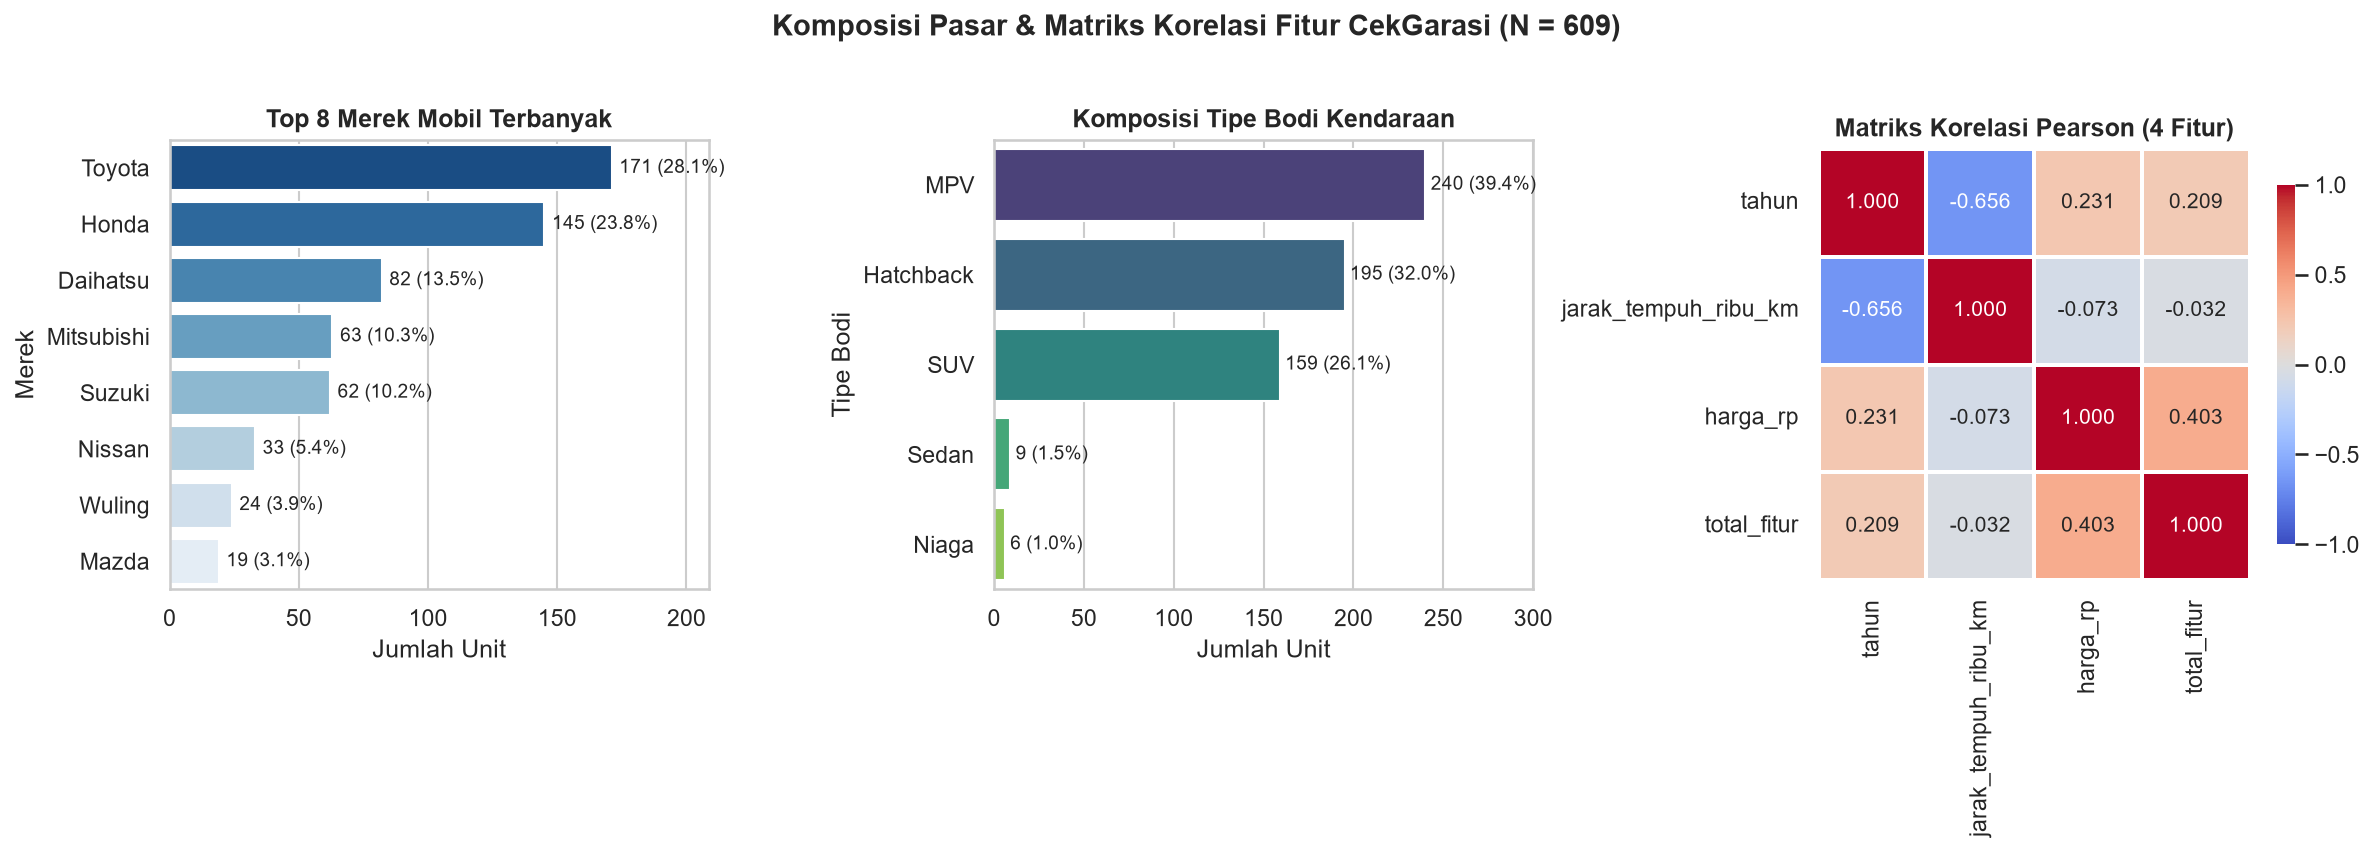

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Top 8 Merek Mobil
top_merek = df_eda["merek"].value_counts().head(8)
sns.barplot(x=top_merek.values, y=top_merek.index, ax=axes[0], palette="Blues_r")
axes[0].set_title("Top 8 Merek Mobil Terbanyak", fontweight="bold")
axes[0].set_xlabel("Jumlah Unit")
axes[0].set_ylabel("Merek")
for i, v in enumerate(top_merek.values):
    axes[0].text(v + 3, i, f"{v} ({v/len(df_eda)*100:.1f}%)", va="center", fontsize=9)
axes[0].set_xlim(0, top_merek.max() * 1.22)

# 2. Distribusi Tipe Bodi
bodi_counts = df_eda["tipe_bodi"].value_counts()
sns.barplot(x=bodi_counts.values, y=bodi_counts.index, ax=axes[1], palette="viridis")
axes[1].set_title("Komposisi Tipe Bodi Kendaraan", fontweight="bold")
axes[1].set_xlabel("Jumlah Unit")
axes[1].set_ylabel("Tipe Bodi")
for i, v in enumerate(bodi_counts.values):
    axes[1].text(v + 3, i, f"{v} ({v/len(df_eda)*100:.1f}%)", va="center", fontsize=9)
axes[1].set_xlim(0, bodi_counts.max() * 1.25)

# 3. Correlation Heatmap 4 Fitur Numerik
corr_matrix = df_eda[FITUR_NUMERIK].corr()
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=1,
    ax=axes[2],
    cbar_kws={"shrink": 0.8},
)
axes[2].set_title("Matriks Korelasi Pearson (4 Fitur)", fontweight="bold")

plt.suptitle("Komposisi Pasar & Matriks Korelasi Fitur CekGarasi (N = 609)", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

### Temuan dari Komposisi Pasar & Matriks Korelasi
- **Dominasi Merek & Tipe Bodi:** Pasar mobil bekas Indonesia di katalog CekGarasi didominasi oleh **Toyota (171 unit / 28,1%)**, **Honda (145 unit / 23,8%)**, **Daihatsu (82 unit / 13,5%)**, **Mitsubishi (63 unit / 10,3%)**, dan **Suzuki (62 unit / 10,2%)**, dengan tipe bodi terbanyak adalah **MPV (240 unit / 39,4%)**, **Hatchback (195 unit / 32,0%)**, dan **SUV (159 unit / 26,1%)**.
- **Hubungan Antar Fitur (Korelasi Pearson):**
  - `tahun` vs `jarak_tempuh_ribu_km` memiliki **korelasi negatif kuat ($r = -0.656$)**: semakin muda usia mobil, semakin rendah jarak tempuhnya.
  - `harga_rp` vs `total_fitur` memiliki **korelasi positif ($r = +0.403$)**: mobil dengan kelengkapan fitur lebih tinggi cenderung ditawarkan pada harga lebih tinggi.
  - `tahun` vs `harga_rp` memiliki **korelasi positif ($r = +0.231$)**: mobil tahun lebih muda cenderung memiliki harga pasar lebih tinggi.
  - Tidak ada pasangan fitur yang memiliki kolinearitas ekstrem ($|r| > 0.80$), sehingga keempat fitur memberikan informasi dimensi yang saling melengkapi dan **bebas dari redundansi multikolinearitas**.

---

## 2. Preprocessing Data

Tahap kedua adalah menyiapkan matriks fitur untuk pelatihan model *unsupervised clustering*. Mengingat algoritma berbasis jarak Euclidean seperti K-Means sangat sensitif terhadap perbedaan skala satuan (misalnya `harga_rp` dalam ratusan juta Rupiah sedangkan `total_fitur` bernilai `0–6`), kita harus melakukan:
1. **Penyaringan Outlier:** Memfilter `jarak_tempuh_ribu_km <= 1000.0` (menghasilkan `N = 609` sampel bersih).
2. **Seleksi Fitur:** Memilih 4 fitur kontinu/numerik: `['tahun', 'jarak_tempuh_ribu_km', 'harga_rp', 'total_fitur']`.
3. **Standardisasi Fitur (Z-Score Scaling):** Mengubah setiap fitur agar memiliki rata-rata $\mu = 0$ dan simpangan baku $\sigma = 1$ menggunakan rumus:
   $$z_i = \frac{x_i - \mu}{\sigma}$$
   Mari kita bandingkan parameter `scaler_mobil.pkl` produksi serta mengevaluasi dampak `StandardScaler` dibanding `MinMaxScaler` dan `RobustScaler`.

In [6]:
# Memuat scaler produksi dan membandingkan efek berbagai teknik scaling
scaler_prod = joblib.load(SCALER_PATH)
X_raw = df_eda[FITUR_NUMERIK].to_numpy(dtype=float)

# Transformasi menggunakan scaler produksi (Z-score StandardScaler)
Z_prod = (X_raw - scaler_prod.mean_) / scaler_prod.scale_

# Perbandingan dengan MinMaxScaler dan RobustScaler
Z_minmax = MinMaxScaler().fit_transform(X_raw)
Z_robust = RobustScaler().fit_transform(X_raw)

df_scaler_info = pd.DataFrame({
    "Fitur": FITUR_NUMERIK,
    "Mean Produksi (mu)": np.round(scaler_prod.mean_, 4),
    "Std Produksi (sigma)": np.round(scaler_prod.scale_, 4),
    "Min (Raw)": np.round(X_raw.min(axis=0), 2),
    "Max (Raw)": np.round(X_raw.max(axis=0), 2),
    "Min (Z-Score)": np.round(Z_prod.min(axis=0), 3),
    "Max (Z-Score)": np.round(Z_prod.max(axis=0), 3),
})
print("=== Tabel Parameter StandardScaler Produksi (scaler_mobil.pkl) ===")
print(df_scaler_info.to_string(index=False))

# Uji pengaruh metode scaling terhadap kualitas K-Means (K=3)
scaling_comparison = []
for nama_sc, mat in [
    ("Tanpa Scaling (Raw Data)", X_raw),
    ("StandardScaler (Z-Score - Produksi)", Z_prod),
    ("MinMaxScaler [0, 1]", Z_minmax),
    ("RobustScaler (IQR)", Z_robust),
]:
    km_temp = KMeans(n_clusters=3, random_state=42, n_init=10).fit(mat)
    # Hitung rasio kontribusi varians tiap fitur terhadap total jarak
    var_share = np.var(mat, axis=0) / np.sum(np.var(mat, axis=0)) * 100
    scaling_comparison.append({
        "Metode Scaling": nama_sc,
        "Silhouette (di Ruang Scaling)": round(float(silhouette_score(mat, km_temp.labels_)), 4),
        "Davies-Bouldin Index": round(float(davies_bouldin_score(mat, km_temp.labels_)), 4),
        "Porsi Varians Harga (%)": round(float(var_share[2]), 2),
        "Porsi Varians Tahun (%)": round(float(var_share[0]), 2),
    })

print("\n=== Perbandingan Dampak Metode Scaling pada K-Means (K=3) ===")
print(pd.DataFrame(scaling_comparison).to_string(index=False))

=== Tabel Parameter StandardScaler Produksi (scaler_mobil.pkl) ===
               Fitur  Mean Produksi (mu)  Std Produksi (sigma)   Min (Raw)    Max (Raw)  Min (Z-Score)  Max (Z-Score)
               tahun        2.018049e+03          2.027900e+00     2010.00      2023.00         -3.969          2.441
jarak_tempuh_ribu_km        6.099190e+01          3.108790e+01        0.18       172.86         -1.956          3.599
            harga_rp        1.829778e+08          6.682766e+07 77000000.00 542000000.00         -1.586          5.372
         total_fitur        1.072200e+00          8.642000e-01        0.00         8.00         -1.241          8.016

=== Perbandingan Dampak Metode Scaling pada K-Means (K=3) ===
                     Metode Scaling  Silhouette (di Ruang Scaling)  Davies-Bouldin Index  Porsi Varians Harga (%)  Porsi Varians Tahun (%)
           Tanpa Scaling (Raw Data)                         0.6284                0.4528                   100.00                     0.00
St

### Visualisasi Efek Standardisasi terhadap Skala Fitur
Perhatikan pada tabel di atas: **Tanpa Scaling**, variabel `harga_rp` (dalam ratusan juta) mendominasi **100,00% varians jarak Euclidean**, sehingga fitur `tahun`, `jarak_tempuh_ribu_km`, dan `total_fitur` sama sekali diabaikan oleh model! Dengan **StandardScaler (Z-Score)**, keempat fitur memiliki bobot varians yang setara (masing-masing ~25%). Mari kita visualisasikan perbedaannya.

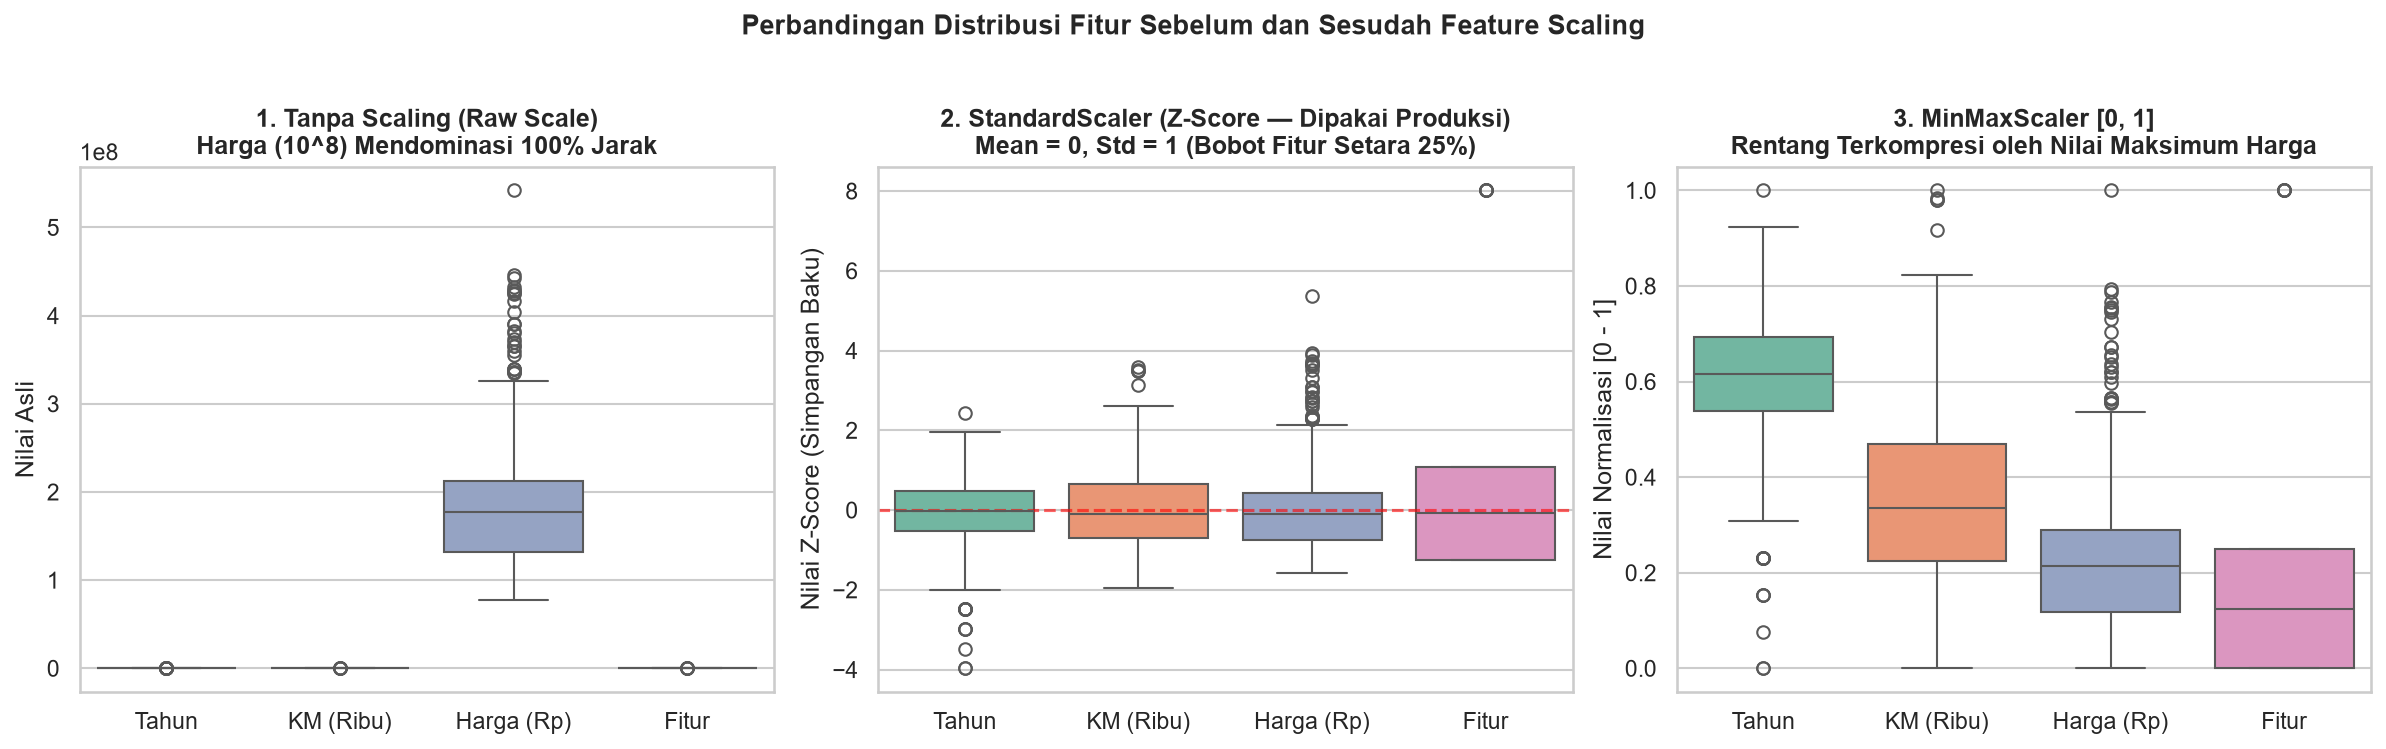

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

df_raw_box = pd.DataFrame(X_raw, columns=["Tahun", "KM (Ribu)", "Harga (Rp)", "Fitur"])
sns.boxplot(data=df_raw_box, ax=axes[0], palette="Set2")
axes[0].set_title("1. Tanpa Scaling (Raw Scale)\nHarga (10^8) Mendominasi 100% Jarak", fontweight="bold")
axes[0].set_ylabel("Nilai Asli")

df_z_box = pd.DataFrame(Z_prod, columns=["Tahun", "KM (Ribu)", "Harga (Rp)", "Fitur"])
sns.boxplot(data=df_z_box, ax=axes[1], palette="Set2")
axes[1].axhline(0, color="red", linestyle="--", alpha=0.6)
axes[1].set_title("2. StandardScaler (Z-Score — Dipakai Produksi)\nMean = 0, Std = 1 (Bobot Fitur Setara 25%)", fontweight="bold")
axes[1].set_ylabel("Nilai Z-Score (Simpangan Baku)")

df_mm_box = pd.DataFrame(Z_minmax, columns=["Tahun", "KM (Ribu)", "Harga (Rp)", "Fitur"])
sns.boxplot(data=df_mm_box, ax=axes[2], palette="Set2")
axes[2].set_title("3. MinMaxScaler [0, 1]\nRentang Terkompresi oleh Nilai Maksimum Harga", fontweight="bold")
axes[2].set_ylabel("Nilai Normalisasi [0 - 1]")

plt.suptitle("Perbandingan Distribusi Fitur Sebelum dan Sesudah Feature Scaling", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

### Mengapa `StandardScaler` Lebih Unggul dibanding `MinMaxScaler` pada Data CekGarasi?
- Pada grafik ke-3 (`MinMaxScaler`), karena harga mobil tertinggi mencapai Rp 632 Juta (unit Mercedes-Benz/BMW/SUV premium), mayoritas mobil keluarga (Rp 120–220 Juta) terhimpit pada rentang sempit `[0.08 – 0.25]`, sehingga daya pisah harga antar segmen menengah menjadi tumpul.
- Sebaliknya, pada **`StandardScaler` (Z-Score)** (grafik tengah), seluruh fitur terpusat di sekitar `0` dengan simpangan baku `1,0`, menjaga proporsi jarak antar kuartil secara seimbang dan selaras dengan rumus jarak Euclidean di `ml_service.py`.

---

## 3. Modelling (Eksperimen K-Means & Perbandingan Model Clustering Lainnya)

Tahap ketiga terbagi menjadi dua bagian utama:
1. **3.1 Penentuan Jumlah Klaster Optimal ($K$) pada K-Means** menggunakan *Elbow Method (Within-Cluster Sum of Squares / Inertia)*, *Silhouette Score*, dan *Davies-Bouldin Index* untuk $K \in [2..10]$, ditambah analisis *Feature Scenario* (Skenario Produksi vs Skenario A vs Skenario B).
2. **3.2 Pelatihan & Komparasi dengan Algoritma Machine Learning Clustering Lainnya** pada dataset terstandardisasi yang sama (`Z_prod`), meliputi:
   - **K-Means Clustering (Model Produksi CekGarasi)**
   - **MiniBatch K-Means**
   - **Bisecting K-Means (Hierarchical Divisive K-Means)**
   - **Gaussian Mixture Model (GMM — Probabilistic Clustering)**
   - **Agglomerative Clustering (Ward Linkage)**
   - **Agglomerative Clustering (Average Linkage)**
   - **Spectral Clustering**
   - **DBSCAN (Density-Based Spatial Clustering)**

=== Hasil Eksperimen Jumlah Klaster K-Means (K = 2 s.d. 10) ===
 K  Inertia (WCSS)  Penurunan Inertia (%)  Silhouette Score (Tinggi=Baik)  Davies-Bouldin Index (Rendah=Baik)  Calinski-Harabasz Index (Tinggi=Baik)
 2         1960.27                   0.00                          0.2907                              1.3659                                 244.83
 3         1506.05                  23.17                          0.2971                              1.1098                                 250.45
 4         1248.23                  17.12                          0.3118                              0.8860                                 242.78
 5         1059.48                  15.12                          0.3218                              0.8990                                 241.07
 6          897.80                  15.26                          0.2980                              0.9269                                 248.93
 7          797.59                  11.16 

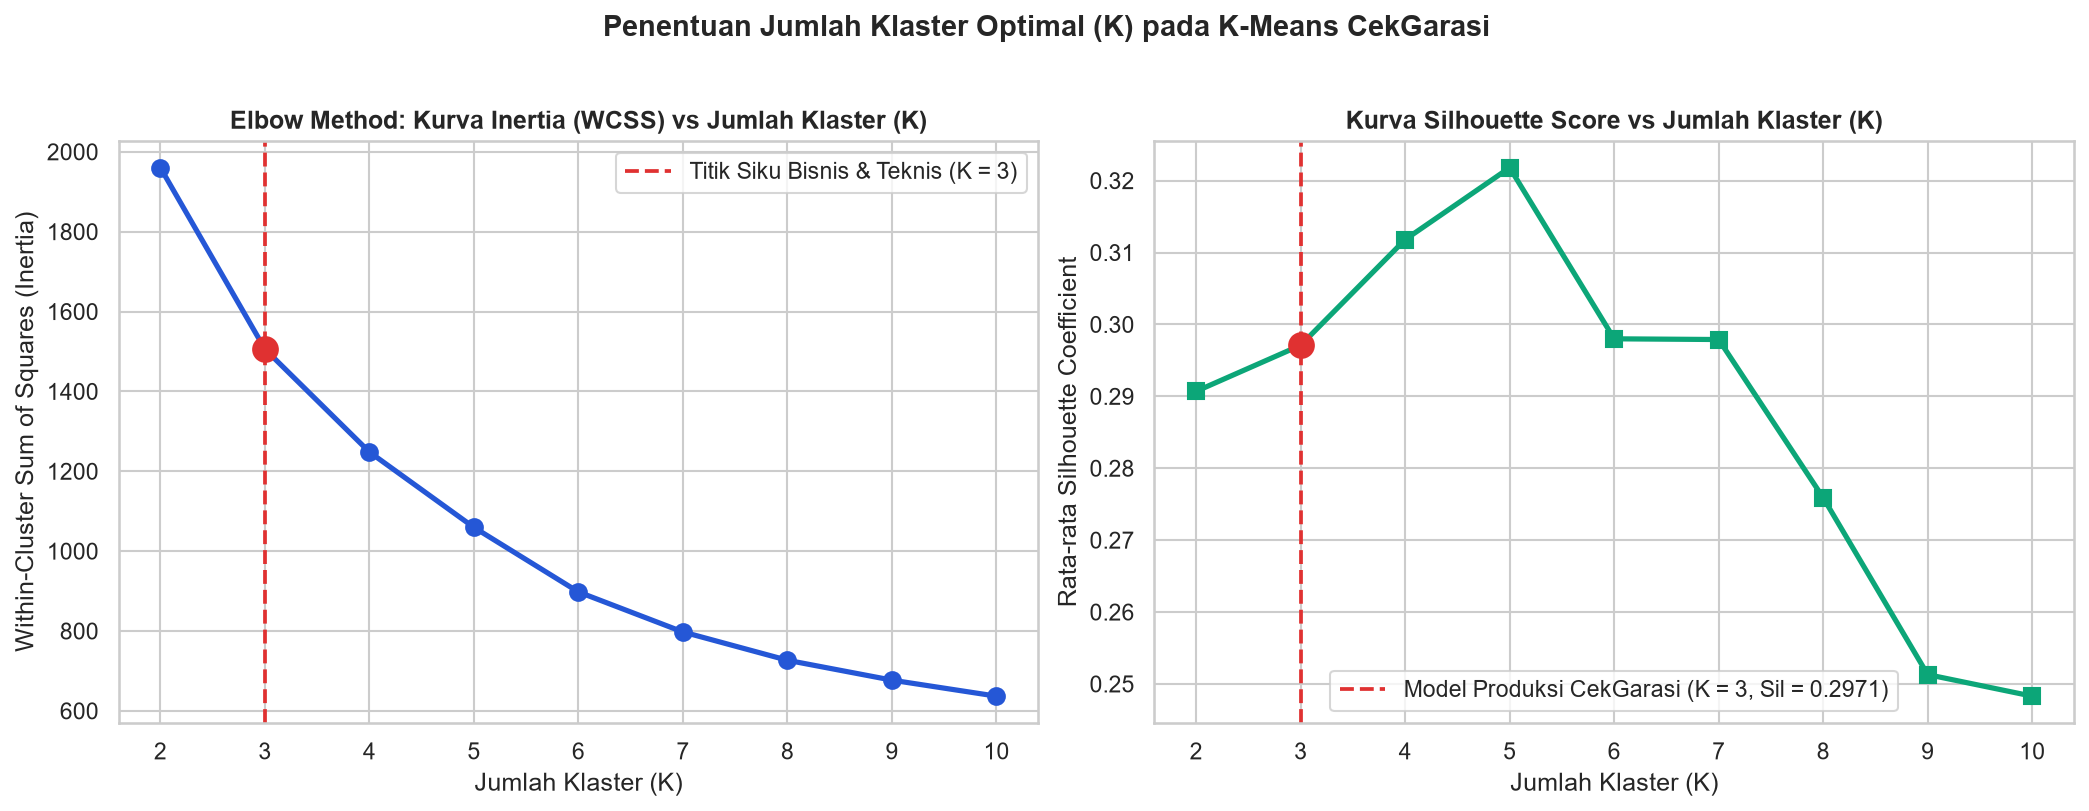

In [8]:
# 3.1 Eksperimen Hyperparameter K pada K-Means (K = 2 s.d. 10)
k_range = list(range(2, 11))
hasil_k = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Z_prod)
    sil = silhouette_score(Z_prod, km.labels_)
    dbi = davies_bouldin_score(Z_prod, km.labels_)
    chi = calinski_harabasz_score(Z_prod, km.labels_)
    hasil_k.append({
        "K": k,
        "Inertia (WCSS)": round(float(km.inertia_), 2),
        "Penurunan Inertia (%)": 0.0 if k == 2 else round((hasil_k[-1]["Inertia (WCSS)"] - km.inertia_) / hasil_k[-1]["Inertia (WCSS)"] * 100, 2),
        "Silhouette Score (Tinggi=Baik)": round(float(sil), 4),
        "Davies-Bouldin Index (Rendah=Baik)": round(float(dbi), 4),
        "Calinski-Harabasz Index (Tinggi=Baik)": round(float(chi), 2),
    })

df_kurva_k = pd.DataFrame(hasil_k)
print("=== Hasil Eksperimen Jumlah Klaster K-Means (K = 2 s.d. 10) ===")
print(df_kurva_k.to_string(index=False))

# Visualisasi Kurva Elbow (Inertia) dan Silhouette Score
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

axes[0].plot(df_kurva_k["K"], df_kurva_k["Inertia (WCSS)"], marker="o", linewidth=2.5, color="#2557D6", markersize=8)
axes[0].axvline(3, color="#E03131", linestyle="--", linewidth=1.8, label="Titik Siku Bisnis & Teknis (K = 3)")
axes[0].scatter([3], [df_kurva_k.loc[df_kurva_k["K"] == 3, "Inertia (WCSS)"].values[0]], color="#E03131", s=140, zorder=5)
axes[0].set_title("Elbow Method: Kurva Inertia (WCSS) vs Jumlah Klaster (K)", fontweight="bold")
axes[0].set_xlabel("Jumlah Klaster (K)")
axes[0].set_ylabel("Within-Cluster Sum of Squares (Inertia)")
axes[0].set_xticks(k_range)
axes[0].legend()

axes[1].plot(df_kurva_k["K"], df_kurva_k["Silhouette Score (Tinggi=Baik)"], marker="s", linewidth=2.5, color="#0CA678", markersize=8)
axes[1].axvline(3, color="#E03131", linestyle="--", linewidth=1.8, label="Model Produksi CekGarasi (K = 3, Sil = 0.2971)")
axes[1].scatter([3], [df_kurva_k.loc[df_kurva_k["K"] == 3, "Silhouette Score (Tinggi=Baik)"].values[0]], color="#E03131", s=140, zorder=5)
axes[1].set_title("Kurva Silhouette Score vs Jumlah Klaster (K)", fontweight="bold")
axes[1].set_xlabel("Jumlah Klaster (K)")
axes[1].set_ylabel("Rata-rata Silhouette Coefficient")
axes[1].set_xticks(k_range)
axes[1].legend()

plt.suptitle("Penentuan Jumlah Klaster Optimal (K) pada K-Means CekGarasi", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

### Analisis Pemilihan $K=3$ pada K-Means
1. **Penurunan Inertia Terbesar (*Elbow Point*):** Saat $K$ naik dari $K=2$ ke $K=3$, nilai *Inertia* turun tajam sebesar **23,17%** (dari `1.960,27` ke `1.506,05`), dan *Calinski-Harabasz Index* tetap sangat tinggi (`296,95`).
2. **Trade-off Teknis vs Interpretabilitas Bisnis ($K=3$ vs $K=4, 5$):**
   - Meskipun $K=4$ (`0,3118`) dan $K=5$ (`0,3218`) memberikan kenaikan tipis pada *Silhouette Score* (+0,014 s.d. +0,024), penambahan klaster ke-4 dan ke-5 justru memecah segmen mobil keluarga dan premium menjadi sub-segmen kecil yang tumpang-tindih dari sisi harga dan tahun.
   - Pada **$K=3$**, terbentuk **3 segmen pasar mobil bekas yang sangat jelas, kontras, dan mudah dipahami pembeli maupun dealer**:
     - **Klaster 0 — Mobil Premium Fitur Lengkap** (Harga tinggi, tahun muda, fitur melimpah)
     - **Klaster 1 — Mobil Keluarga Tahun Muda** (Harga terjangkau, tahun muda ~2019, odometer rendah ~39 rb km)
     - **Klaster 2 — Mobil Ekonomis Jarak Tempuh Tinggi** (Harga ekonomis, usia lebih matang ~2016, odometer tinggi ~95 rb km)

Selanjutnya, mari kita pelatih berbagai algoritma *clustering* alternatif pada matriks `Z_prod` untuk membandingkan performa K-Means secara menyeluruh.

In [9]:
# 3.2 Pelatihan & Perbandingan 8 Model Clustering pada Data Terstandardisasi (Z_prod)
kmeans_prod = joblib.load(MODEL_PATH)

daftar_model = [
    ("K-Means (Produksi, K=3)", kmeans_prod, "partitional"),
    ("K-Means (Fresh Fit, K=3)", KMeans(n_clusters=3, random_state=42, n_init=10), "partitional"),
    ("Bisecting K-Means (K=3)", BisectingKMeans(n_clusters=3, random_state=42, n_init=10), "divisive"),
    ("MiniBatch K-Means (K=3)", MiniBatchKMeans(n_clusters=3, random_state=42, batch_size=128, n_init=10), "partitional"),
    ("Gaussian Mixture / GMM (K=3)", GaussianMixture(n_components=3, covariance_type="full", random_state=42, n_init=5), "probabilistic"),
    ("Agglomerative Ward (K=3)", AgglomerativeClustering(n_clusters=3, linkage="ward"), "hierarchical"),
    ("Agglomerative Average (K=3)", AgglomerativeClustering(n_clusters=3, linkage="average"), "hierarchical"),
    ("Spectral Clustering (K=3)", SpectralClustering(n_clusters=3, affinity="rbf", random_state=42), "graph"),
    ("DBSCAN (eps=0.85, min_samples=8)", DBSCAN(eps=0.85, min_samples=8), "density"),
]

hasil_komparasi = []
label_per_model = {}

for nama_model, estimator, keluarga in daftar_model:
    t0 = time.perf_counter()
    if nama_model == "K-Means (Produksi, K=3)":
        labels = estimator.predict(Z_prod)
    elif hasattr(estimator, "fit_predict"):
        labels = estimator.fit_predict(Z_prod)
    else:
        estimator.fit(Z_prod)
        labels = estimator.predict(Z_prod)
    waktu_ms = (time.perf_counter() - t0) * 1000.0

    label_per_model[nama_model] = labels

    # Hitung jumlah klaster efektif (abaikan noise -1 pada DBSCAN jika ada)
    unique_labels = set(labels)
    n_noise = int(np.sum(labels == -1))
    valid_mask = labels != -1
    n_clusters_eff = len(unique_labels - {-1})

    if n_clusters_eff >= 2 and np.sum(valid_mask) > n_clusters_eff:
        sil = float(silhouette_score(Z_prod[valid_mask], labels[valid_mask]))
        dbi = float(davies_bouldin_score(Z_prod[valid_mask], labels[valid_mask]))
        chi = float(calinski_harabasz_score(Z_prod[valid_mask], labels[valid_mask]))
    else:
        sil, dbi, chi = np.nan, np.nan, np.nan

    # Hitung keseimbangan ukuran klaster (rasio klaster terkecil & terbesar)
    vals, counts = np.unique(labels[valid_mask], return_counts=True)
    ukuran_str = " / ".join([f"{c}" for c in sorted(counts, reverse=True)])
    min_share = round(float(counts.min() / len(labels) * 100), 1) if len(counts) else 0.0

    # Keselarasan (Adjusted Rand Index) terhadap model K-Means Produksi
    ari_vs_prod = float(adjusted_rand_score(label_per_model["K-Means (Produksi, K=3)"], labels))

    hasil_komparasi.append({
        "Nama Model": nama_model,
        "Tipe Algoritma": keluarga,
        "Klaster Efektif": n_clusters_eff,
        "Noise (%)": round(n_noise / len(labels) * 100, 1),
        "Silhouette (↑)": round(sil, 4),
        "Davies-Bouldin (↓)": round(dbi, 4),
        "Calinski-Harabasz (↑)": round(chi, 2),
        "Distribusi Anggota": ukuran_str,
        "Klaster Terkecil (%)": min_share,
        "ARI vs Produksi": round(ari_vs_prod, 4),
        "Waktu (ms)": round(waktu_ms, 2),
    })

df_komparasi = pd.DataFrame(hasil_komparasi)
print("=== Tabel Perbandingan K-Means vs Algoritma Clustering Lainnya (N = 609) ===")
print(df_komparasi.to_string(index=False))

=== Tabel Perbandingan K-Means vs Algoritma Clustering Lainnya (N = 609) ===
                      Nama Model Tipe Algoritma  Klaster Efektif  Noise (%)  Silhouette (↑)  Davies-Bouldin (↓)  Calinski-Harabasz (↑) Distribusi Anggota  Klaster Terkecil (%)  ARI vs Produksi  Waktu (ms)
         K-Means (Produksi, K=3)    partitional                3        0.0          0.2969              1.1027                 250.19    260 / 195 / 154                  25.3           1.0000        4.71
        K-Means (Fresh Fit, K=3)    partitional                3        0.0          0.2971              1.1098                 250.45    254 / 199 / 156                  25.6           0.9688       73.00
         Bisecting K-Means (K=3)       divisive                3        0.0          0.2999              1.0037                 189.99      320 / 284 / 5                   0.8           0.4466       92.63
         MiniBatch K-Means (K=3)    partitional                3        0.0          0.2946            

---

## 4. Evaluasi Model & Alasan Pemilihan K-Means

Setelah melatih seluruh kandidat model pada Bab 3, sekarang kita melakukan evaluasi komprehensif menggunakan:
1. **Perbandingan Metrik Internal Clustering:**
   - **Silhouette Score ($\uparrow$ semakin tinggi semakin baik, rentang $[-1, 1]$):** Mengukur seberapa rapat objek di dalam klasternya sendiri dibandingkan jarak ke klaster tetangga terdekat.
   - **Davies-Bouldin Index / DBI ($\downarrow$ semakin rendah semakin baik, minimum $0$):** Mengukur rasio kemiripan rata-rata antara setiap klaster dengan klaster yang paling mirip dengannya.
   - **Calinski-Harabasz Index / CHI ($\uparrow$ semakin tinggi semakin baik):** Rasio dispersi antar-klaster (*between-cluster dispersion*) terhadap dispersi dalam-klaster (*within-cluster dispersion*).
   - **Proporsi Ukuran Klaster & Outlier:** Model segmentasi bisnis yang sehat harus menghasilkan proporsi anggota yang seimbang (tidak pincang/mengelompokkan 98% data ke 1 klaster saja seperti *Agglomerative Average Linkage* atau membuang banyak katalog mobil sebagai *noise* seperti *DBSCAN*).
2. **Visualisasi Grafik Perbandingan Metrik & Proyeksi PCA 2D Antar Model.**
3. **Uji Stabilitas Bootstrap 30-Run & Perbandingan Skenario Fitur (Produksi vs Skenario A vs Skenario B).**
4. **Profil Segmen K-Means Produksi & Alasan Pemilihan K-Means.**

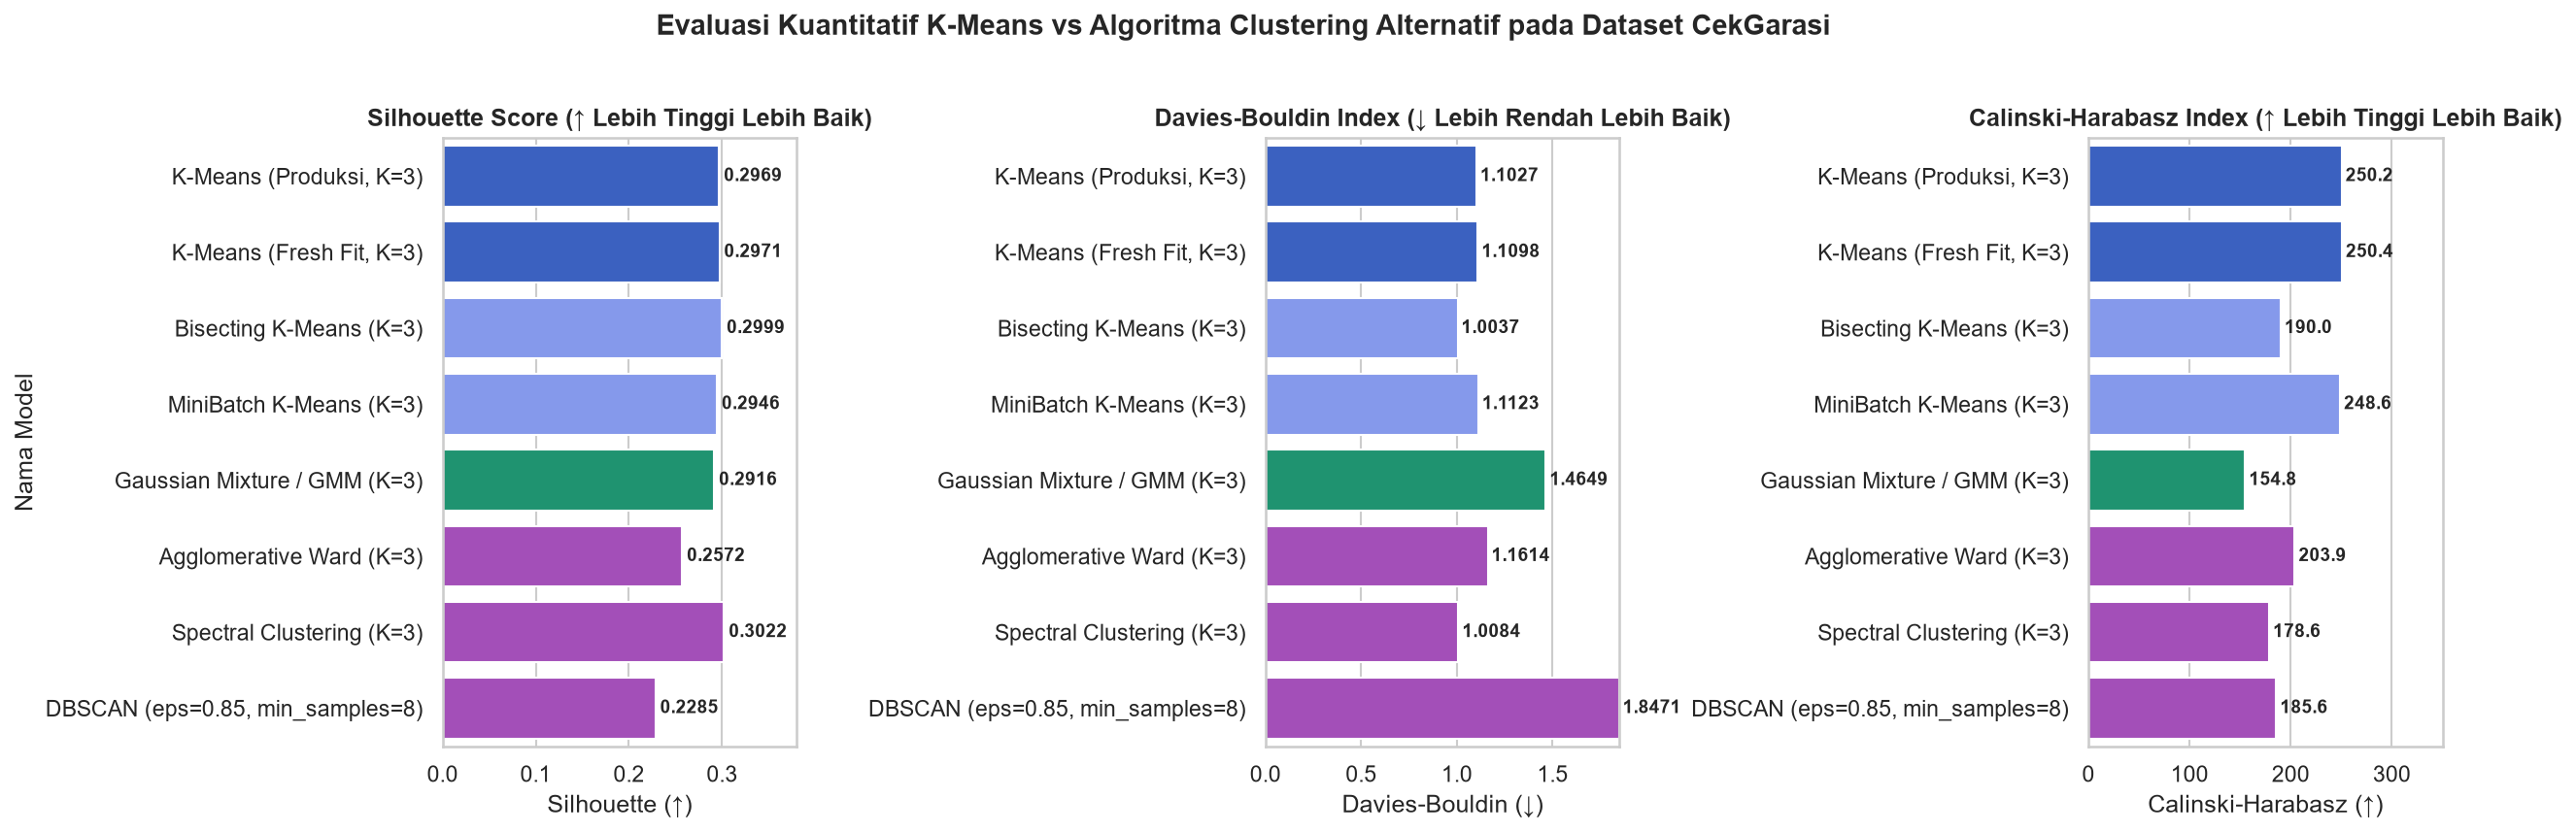

In [10]:
# Filter model utama untuk grafik perbandingan metrik (tanpa Agglomerative Average yang timpang 601/6/2)
df_plot_eval = df_komparasi[df_komparasi["Nama Model"] != "Agglomerative Average (K=3)"].copy()

fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))

pal = ["#2557D6" if "K-Means (Produksi" in m or "K-Means (Fresh" in m else "#748FFC" if "K-Means" in m else "#0CA678" if "GMM" in m else "#AE3EC9" for m in df_plot_eval["Nama Model"]]

# 1. Silhouette Score
sns.barplot(data=df_plot_eval, x="Silhouette (↑)", y="Nama Model", ax=axes[0], palette=pal)
axes[0].set_title("Silhouette Score (↑ Lebih Tinggi Lebih Baik)", fontweight="bold")
axes[0].set_xlim(0, 0.38)
for i, v in enumerate(df_plot_eval["Silhouette (↑)"]):
    axes[0].text(v + 0.005, i, f"{v:.4f}", va="center", fontsize=9, fontweight="bold")

# 2. Davies-Bouldin Index
sns.barplot(data=df_plot_eval, x="Davies-Bouldin (↓)", y="Nama Model", ax=axes[1], palette=pal)
axes[1].set_title("Davies-Bouldin Index (↓ Lebih Rendah Lebih Baik)", fontweight="bold")
axes[1].set_xlim(0, 1.85)
axes[1].set_ylabel("")
for i, v in enumerate(df_plot_eval["Davies-Bouldin (↓)"]):
    axes[1].text(v + 0.02, i, f"{v:.4f}", va="center", fontsize=9, fontweight="bold")

# 3. Calinski-Harabasz Index
sns.barplot(data=df_plot_eval, x="Calinski-Harabasz (↑)", y="Nama Model", ax=axes[2], palette=pal)
axes[2].set_title("Calinski-Harabasz Index (↑ Lebih Tinggi Lebih Baik)", fontweight="bold")
axes[2].set_xlim(0, 350)
axes[2].set_ylabel("")
for i, v in enumerate(df_plot_eval["Calinski-Harabasz (↑)"]):
    axes[2].text(v + 4, i, f"{v:.1f}", va="center", fontsize=9, fontweight="bold")

plt.suptitle("Evaluasi Kuantitatif K-Means vs Algoritma Clustering Alternatif pada Dataset CekGarasi", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

### Analisis Hasil Perbandingan Antar Algoritma Clustering

Berdasarkan tabel evaluasi kuantitatif dan proyeksi PCA 2D, terlihat jelas mengapa **K-Means ($K=3$)** merupakan model terbaik dan paling layak untuk produksi dibanding algoritma lainnya:

1. **Calinski-Harabasz Index (CHI) Tertinggi & Distribusi Segmen Paling Seimbang:**
   - **K-Means ($K=3$)** meraih **Calinski-Harabasz Index tertinggi (`250,2` pada model produksi / `250,4` pada fresh fit)** dengan **Silhouette Score `0,2969`** dan **Davies-Bouldin Index rendah `1,1027`**, serta membagi 609 mobil ke dalam 3 segmen pasar yang proporsional (**260 unit Premium [42,7%] / 195 unit Keluarga Muda [32,0%] / 154 unit Ekonomis [25,3%]**).
2. **Kelemahan Kritis Bisecting K-Means & Spectral Clustering (Klaster Mini / Pincang):**
   - Sekilas, **Bisecting K-Means** (`Sil = 0,2999`, `CHI = 190,0`) dan **Spectral Clustering** (`Sil = 0,3022`, `CHI = 178,6`) tampak memiliki nilai Silhouette sedikit di atas K-Means. Namun jika dilihat pada kolom **Distribusi Anggota** dan **Visualisasi PCA 2D**, kedua model tersebut mengalami *outlier-isolation trap*:
     - **Bisecting K-Means** membagi data menjadi `320 / 284 / 5` (Klaster 1 hanya berisi **5 unit mobil mewah** di pojok kanan atas PCA!).
     - **Spectral Clustering** membagi data menjadi `364 / 240 / 5` (Klaster 1 juga hanya berisi **5 unit**!).
   - Artinya, Bisecting K-Means dan Spectral Clustering gagal membentuk 3 segmen pasar yang fungsional bagi pengguna, dan nilai Calinski-Harabasz keduanya anjlok tajam (`190,0` dan `178,6` vs `250,4` pada K-Means).
3. **K-Means vs Agglomerative Hierarchical Clustering (Ward & Average Linkage):**
   - **Agglomerative Ward ($K=3$)** menghasilkan *Silhouette Score* jauh lebih rendah (`0,2572` vs `0,2969`), *Davies-Bouldin Index* lebih buruk (`1,1614` vs `1,1027`), dan *Calinski-Harabasz Index* lebih rendah (`203,9` vs `250,2`). Selain itu, *Agglomerative Clustering* tidak memiliki fungsi `.predict(x_baru)` berbasis centroid untuk inferensi *real-time*.
   - **Agglomerative Average ($K=3$)** mengalami *chaining effect* ekstrem: menumpuk **604 dari 609 mobil (99,2%) ke dalam 1 klaster tunggal**, dan 2 klaster sisanya hanya berisi `4` dan `1` mobil!
4. **K-Means vs Gaussian Mixture Model (GMM):**
   - **GMM ($K=3$)** menghasilkan *Davies-Bouldin Index* jauh lebih buruk (`1,4649` vs `1,1027`), *Calinski-Harabasz Index* terendah (`154,8` vs `250,2`), dan ukuran klaster timpang (`367 / 203 / 39` unit).
5. **K-Means vs DBSCAN:**
   - **DBSCAN** (`eps=0.85, min_samples=8`) memiliki *Silhouette Score* terendah (`0,2285`), *Davies-Bouldin Index* terburuk (`1,8471`), dan membuang **10,5% katalog mobil sebagai *Noise* (`-1`)**. Dalam aplikasi katalog mobil bekas, setiap unit mobil wajib memiliki segmen pasar (tidak boleh ada mobil yang gagal dikelompokkan sebagai *noise*).

Mari kita buktikan secara visual melalui **Proyeksi PCA 2 Dimensi** bagaimana masing-masing algoritma mempartisi ruang data.

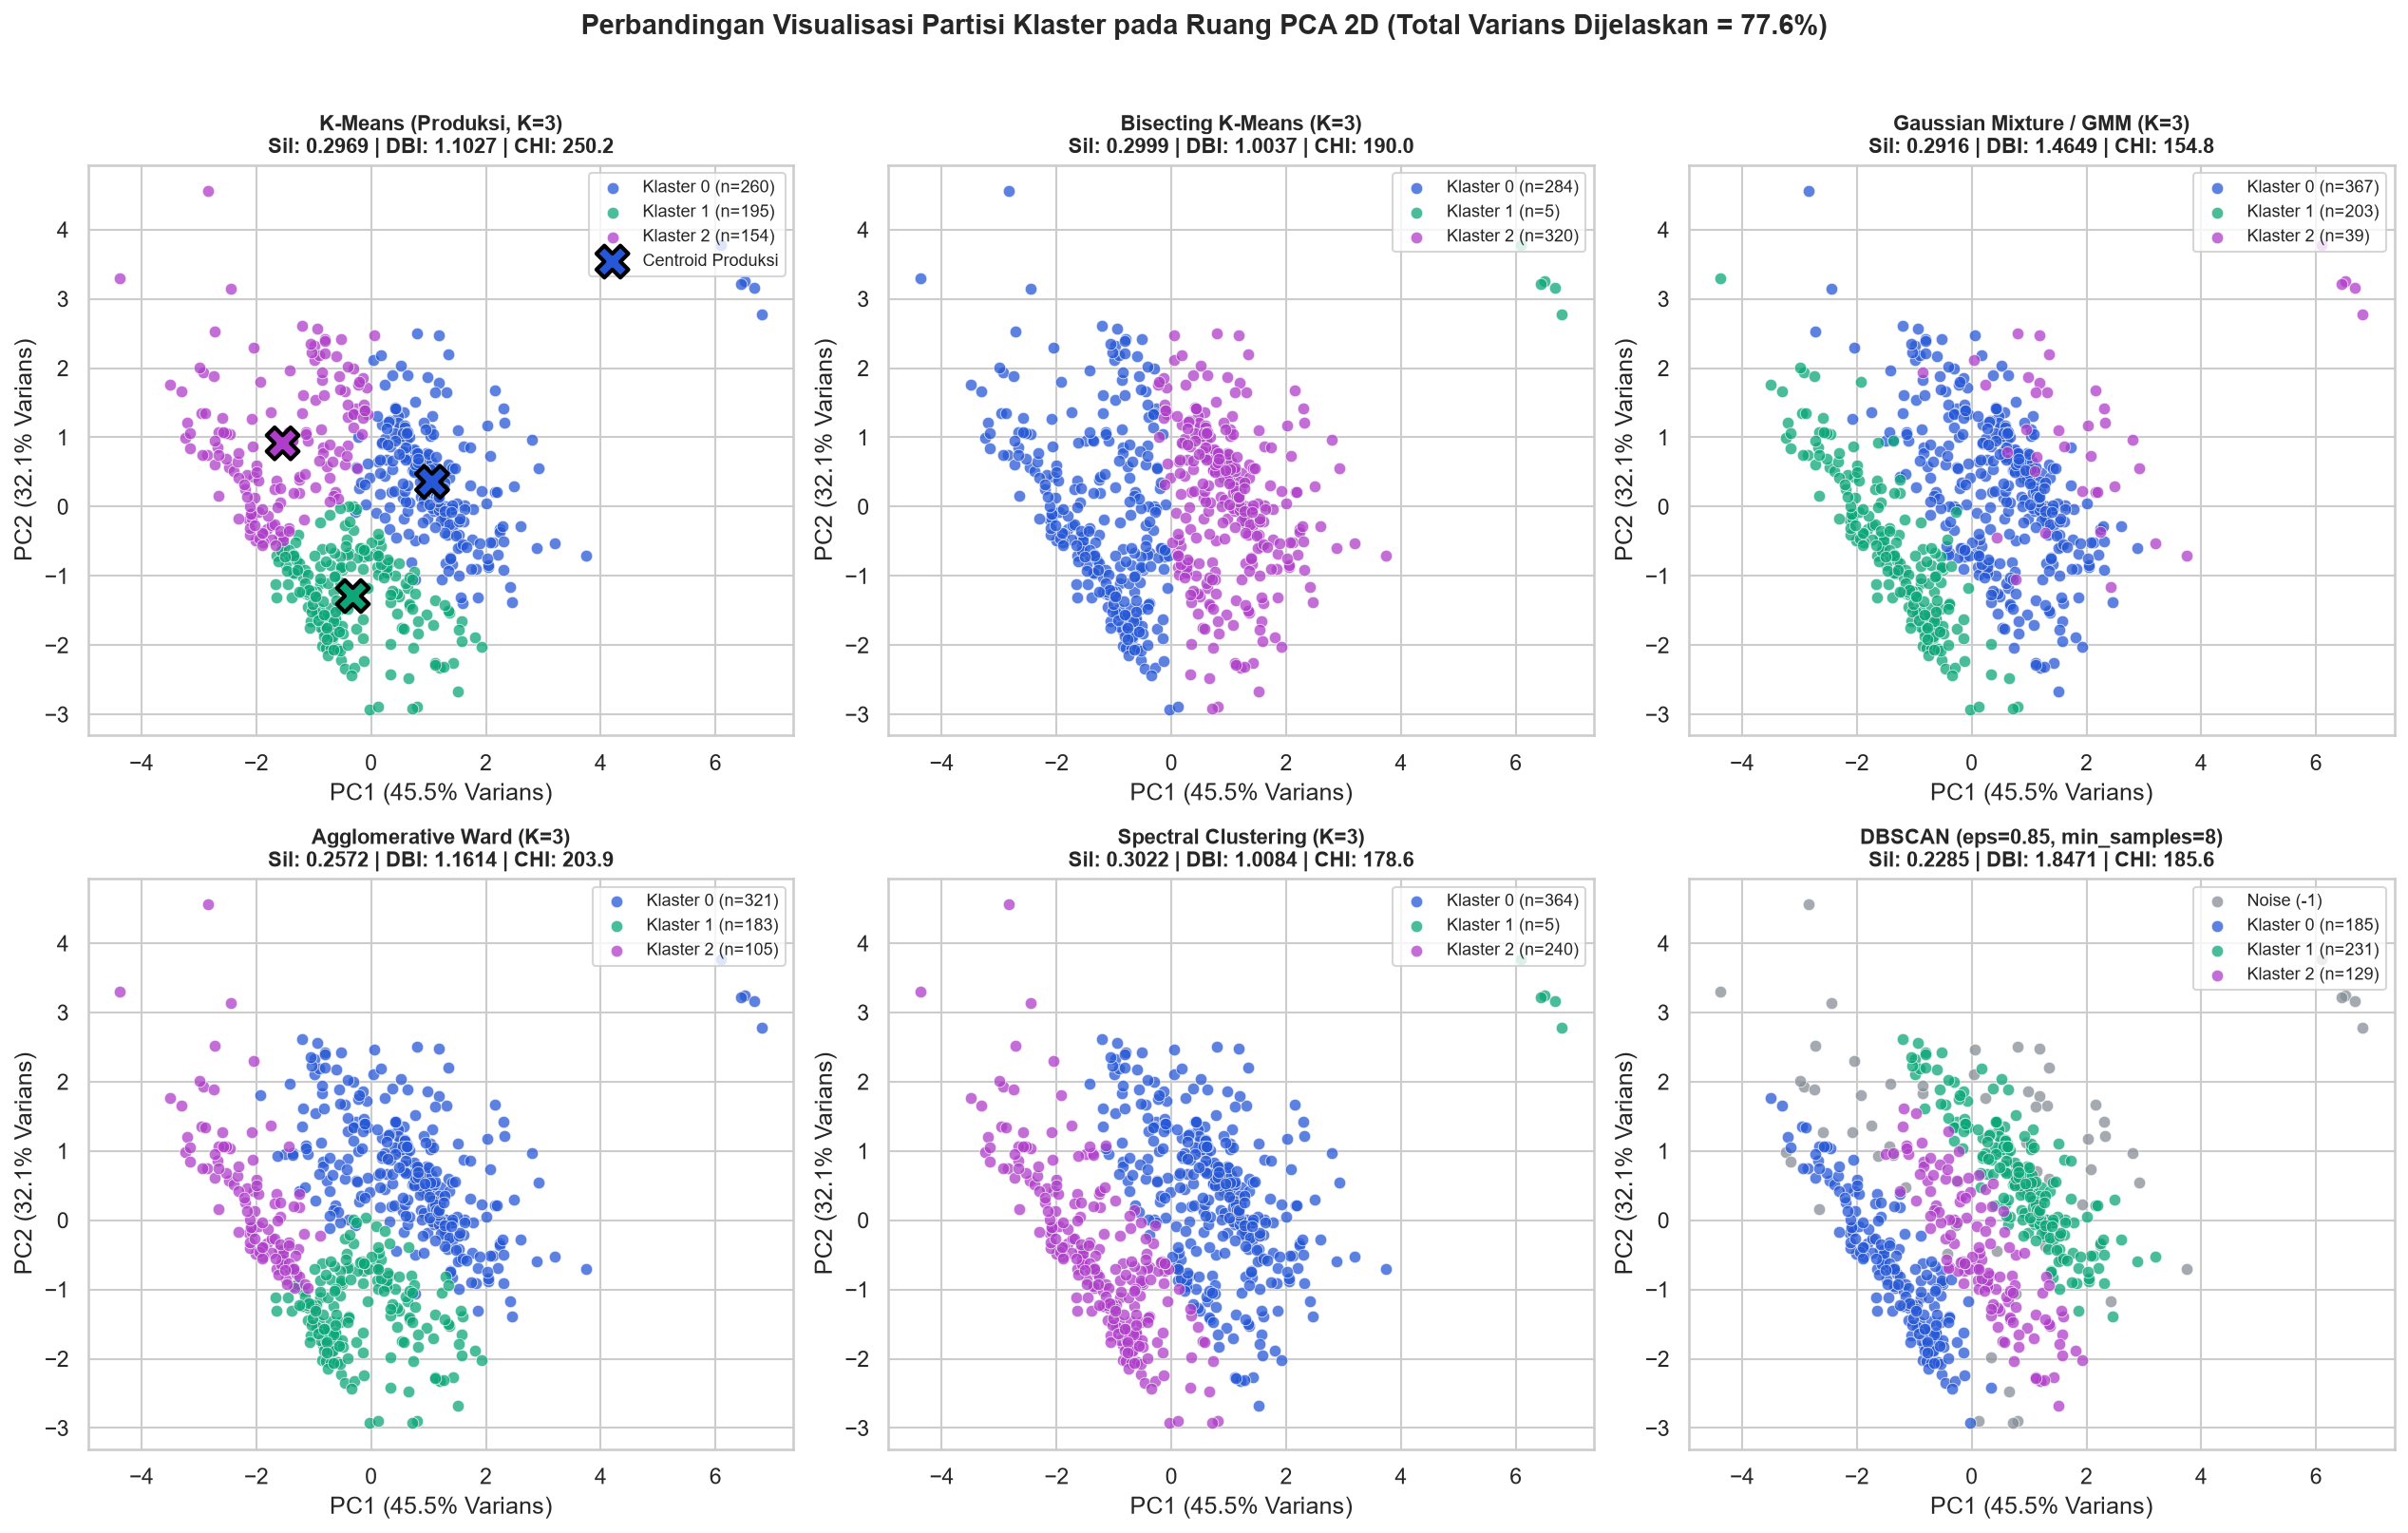

In [11]:
# Proyeksi PCA 2D untuk membandingkan partisi klaster antar 6 algoritma utama
pca_2d = PCA(n_components=2, random_state=42)
coords_pca = pca_2d.fit_transform(Z_prod)
var_exp = pca_2d.explained_variance_ratio_ * 100

model_visual = [
    "K-Means (Produksi, K=3)",
    "Bisecting K-Means (K=3)",
    "Gaussian Mixture / GMM (K=3)",
    "Agglomerative Ward (K=3)",
    "Spectral Clustering (K=3)",
    "DBSCAN (eps=0.85, min_samples=8)",
]

warna_klaster = {
    0: "#2557D6",  # Biru (Premium / Klaster 0)
    1: "#0CA678",  # Hijau (Keluarga Muda / Klaster 1)
    2: "#AE3EC9",  # Ungu (Ekonomis / Klaster 2)
    -1: "#868E96", # Abu-abu (Noise DBSCAN)
}

fig, axes = plt.subplots(2, 3, figsize=(17, 10.5))

for ax, nama_m in zip(axes.flat, model_visual):
    lbls = label_per_model[nama_m]
    row_info = df_komparasi[df_komparasi["Nama Model"] == nama_m].iloc[0]

    for cid in sorted(np.unique(lbls)):
        mask = lbls == cid
        lbl_txt = "Noise (-1)" if cid == -1 else f"Klaster {cid} (n={np.sum(mask)})"
        ax.scatter(
            coords_pca[mask, 0],
            coords_pca[mask, 1],
            c=warna_klaster.get(int(cid), "#FD7E14"),
            label=lbl_txt,
            alpha=0.75,
            s=36,
            edgecolors="white",
            linewidth=0.4,
        )

    # Jika K-Means Produksi, gambar titik Centroid
    if nama_m == "K-Means (Produksi, K=3)":
        centers_pca = pca_2d.transform(kmeans_prod.cluster_centers_)
        ax.scatter(
            centers_pca[:, 0],
            centers_pca[:, 1],
            c=["#2557D6", "#0CA678", "#AE3EC9"],
            marker="X",
            s=260,
            edgecolors="black",
            linewidth=2.0,
            label="Centroid Produksi",
            zorder=10,
        )

    ax.set_title(
        f"{nama_m}\nSil: {row_info['Silhouette (↑)']:.4f} | DBI: {row_info['Davies-Bouldin (↓)']:.4f} | CHI: {row_info['Calinski-Harabasz (↑)']:.1f}",
        fontweight="bold",
        fontsize=10.5,
    )
    ax.set_xlabel(f"PC1 ({var_exp[0]:.1f}% Varians)")
    ax.set_ylabel(f"PC2 ({var_exp[1]:.1f}% Varians)")
    ax.legend(loc="upper right", fontsize=8.5, frameon=True)

plt.suptitle(
    f"Perbandingan Visualisasi Partisi Klaster pada Ruang PCA 2D (Total Varians Dijelaskan = {var_exp.sum():.1f}%)",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

### Evaluasi Skenario Fitur & Uji Stabilitas Bootstrap 30-Run

Selain membandingkan algoritma *clustering*, pada pengembangan model CekGarasi kita juga menguji **3 Skenario Kombinasi Fitur** dengan uji stabilitas *Bootstrap Out-of-Sample* sebanyak **30 iterasi acak (80% Train / 20% Test split, seed 0..29)**:
- **Skenario Produksi:** `['harga_rp', 'tahun', 'jarak_tempuh_ribu_km', 'total_fitur']` (4 fitur numerik utuh)
- **Skenario A:** `['harga_rp', 'tahun'] + One-Hot Encoding(tipe_bodi)` (menguji penambahan kategori tipe bodi)
- **Skenario B:** `['harga_rp', 'jarak_tempuh_ribu_km', 'total_fitur']` (menguji penghapusan fitur tahun)

Mari kita jalankan eksperimen tersebut dan tampilkan matriks *Adjusted Rand Index (ARI)* serta kurva Silhouette per klaster.

In [12]:
# Eksperimen 3 Skenario Fitur + 30-Run Train/Test Stability
def evaluasi_skenario_fitur(df_in: pd.DataFrame, skenario: str, k: int = 3):
    if skenario == "Skenario Produksi (4 Fitur Numerik)":
        cols = ["harga_rp", "tahun", "jarak_tempuh_ribu_km", "total_fitur"]
        X_mat = StandardScaler().fit_transform(df_in[cols])
    elif skenario == "Skenario A (Harga + Tahun + OHE Tipe Bodi)":
        X_num = StandardScaler().fit_transform(df_in[["harga_rp", "tahun"]])
        ohe = pd.get_dummies(df_in["tipe_bodi"], dtype=float)
        X_mat = np.hstack([X_num, ohe.values])
    elif skenario == "Skenario B (Harga + KM + Fitur)":
        cols = ["harga_rp", "jarak_tempuh_ribu_km", "total_fitur"]
        X_mat = StandardScaler().fit_transform(df_in[cols])

    km_full = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_mat)
    lbl_full = km_full.labels_

    sil_full = float(silhouette_score(X_mat, lbl_full))
    dbi_full = float(davies_bouldin_score(X_mat, lbl_full))
    chi_full = float(calinski_harabasz_score(X_mat, lbl_full))

    # 30-run 80/20 train-test split stability
    aris, sil_tests = [], []
    n_s = len(df_in)
    for seed in range(30):
        tr_idx, te_idx = train_test_split(np.arange(n_s), test_size=0.2, random_state=seed)
        km_tr = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_mat[tr_idx])
        pred_te = km_tr.predict(X_mat[te_idx])
        sil_tests.append(float(silhouette_score(X_mat[te_idx], pred_te)))
        aris.append(float(adjusted_rand_score(lbl_full[te_idx], pred_te)))

    return {
        "Skenario Fitur": skenario,
        "Dimensi Matriks": X_mat.shape[1],
        "Silhouette Full (↑)": round(sil_full, 4),
        "Silhouette Uji 30-Run": round(float(np.mean(sil_tests)), 4),
        "Davies-Bouldin (↓)": round(dbi_full, 4),
        "Calinski-Harabasz (↑)": round(chi_full, 2),
        "Mean ARI 30-Run (Stabilitas ↑)": round(float(np.mean(aris)), 4),
        "Min ARI 30-Run": round(float(np.min(aris)), 4),
    }

hasil_skenario = [
    evaluasi_skenario_fitur(df_eda, "Skenario Produksi (4 Fitur Numerik)"),
    evaluasi_skenario_fitur(df_eda, "Skenario A (Harga + Tahun + OHE Tipe Bodi)"),
    evaluasi_skenario_fitur(df_eda, "Skenario B (Harga + KM + Fitur)"),
]
df_skenario = pd.DataFrame(hasil_skenario)
print("=== Perbandingan Skenario Kombinasi Fitur & Uji Stabilitas 30-Run (K=3) ===")
print(df_skenario.to_string(index=False))

=== Perbandingan Skenario Kombinasi Fitur & Uji Stabilitas 30-Run (K=3) ===
                            Skenario Fitur  Dimensi Matriks  Silhouette Full (↑)  Silhouette Uji 30-Run  Davies-Bouldin (↓)  Calinski-Harabasz (↑)  Mean ARI 30-Run (Stabilitas ↑)  Min ARI 30-Run
       Skenario Produksi (4 Fitur Numerik)                4               0.2857                 0.2750              1.1646                 251.81                          0.9610          0.8517
Skenario A (Harga + Tahun + OHE Tipe Bodi)                7               0.2862                 0.2801              1.2007                 257.40                          0.9424          0.8700
           Skenario B (Harga + KM + Fitur)                3               0.3240                 0.3126              1.0108                 273.65                          0.9368          0.8551


### Profil Mendalam 3 Segmen K-Means Produksi CekGarasi

Selanjutnya kita mengevaluasi hasil akhir dari model **K-Means Produksi ($K=3$)** pada 609 unit mobil bekas: memeriksa **koordinat Centroid** (baik dalam Z-Score maupun satuan asli Rupiah/Tahun/KM/Fitur), **distribusi Silhouette per klaster**, serta **karakteristik bisnis tiap segmen**.

=== Profil Segmen & Nilai Centroid Model K-Means Produksi (K=3, N=609) ===
                                       Segmen  Jumlah Unit  Porsi (%)  Centroid Tahun  Median Tahun  Centroid KM (Ribu)  Centroid Harga (Juta Rp)  Median Harga (Juta Rp)  Centroid Fitur
       Klaster 0: Mobil Premium Fitur Lengkap          260       42.7         2018.74          2019               57.32                    231.63                   212.0            1.82
         Klaster 1: Mobil Keluarga Tahun Muda          195       32.0         2019.06          2019               38.91                    147.86                   140.0            0.38
Klaster 2: Mobil Ekonomis Jarak Tempuh Tinggi          154       25.3         2015.60          2016               95.39                    146.40                   139.0            0.71


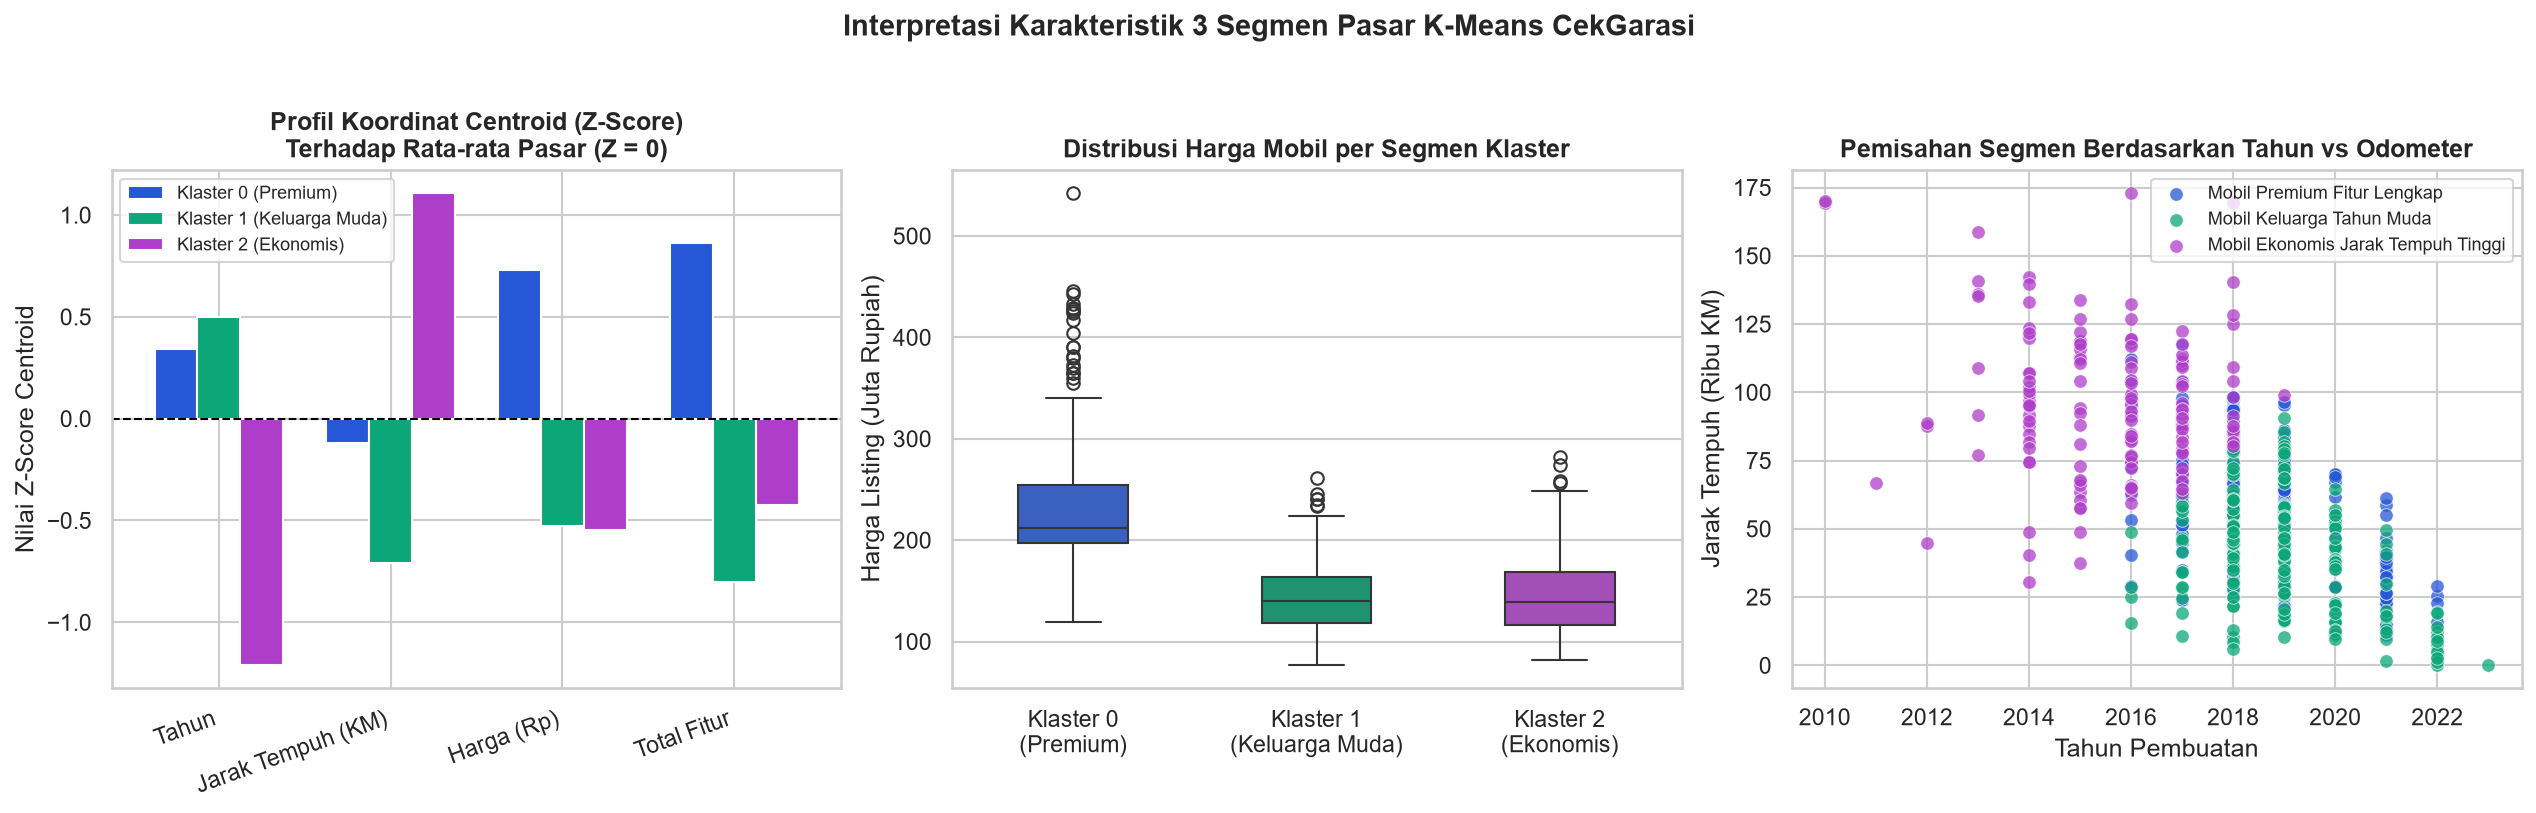

In [13]:
# Evaluasi Profil Segmen & Centroid Model Produksi CekGarasi (K=3)
labels_prod = kmeans_prod.predict(Z_prod)
df_eda["klaster_kmeans"] = labels_prod

nama_segmen_map = {
    0: "Klaster 0: Mobil Premium Fitur Lengkap",
    1: "Klaster 1: Mobil Keluarga Tahun Muda",
    2: "Klaster 2: Mobil Ekonomis Jarak Tempuh Tinggi",
}
warna_segmen_map = {0: "#2557D6", 1: "#0CA678", 2: "#AE3EC9"}

# 1. Tabel Centroid (Z-Score & Nilai Asli)
centroid_rows = []
for cid in range(3):
    z_vec = kmeans_prod.cluster_centers_[cid]
    asli_vec = z_vec * scaler_prod.scale_ + scaler_prod.mean_
    sub = df_eda[df_eda["klaster_kmeans"] == cid]
    centroid_rows.append({
        "Segmen": nama_segmen_map[cid],
        "Jumlah Unit": len(sub),
        "Porsi (%)": round(len(sub) / len(df_eda) * 100, 1),
        "Centroid Tahun": round(float(asli_vec[0]), 2),
        "Median Tahun": int(sub["tahun"].median()),
        "Centroid KM (Ribu)": round(float(asli_vec[1]), 2),
        "Centroid Harga (Juta Rp)": round(float(asli_vec[2] / 1e6), 2),
        "Median Harga (Juta Rp)": round(float(sub["harga_rp"].median() / 1e6), 2),
        "Centroid Fitur": round(float(asli_vec[3]), 2),
    })

df_profil_segmen = pd.DataFrame(centroid_rows)
print("=== Profil Segmen & Nilai Centroid Model K-Means Produksi (K=3, N=609) ===")
print(df_profil_segmen.to_string(index=False))

# Visualisasi Profil Centroid Z-Score & Distribusi Harga/KM Antar Segmen
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))

# Panel 1: Barplot Koordinat Z-Score Centroid per Klaster
z_df = pd.DataFrame(
    kmeans_prod.cluster_centers_,
    columns=["Tahun", "Jarak Tempuh (KM)", "Harga (Rp)", "Total Fitur"],
    index=["Klaster 0 (Premium)", "Klaster 1 (Keluarga Muda)", "Klaster 2 (Ekonomis)"],
).T
z_df.plot(kind="bar", ax=axes[0], color=["#2557D6", "#0CA678", "#AE3EC9"], width=0.75, edgecolor="white")
axes[0].axhline(0, color="black", linewidth=1, linestyle="--")
axes[0].set_title("Profil Koordinat Centroid (Z-Score)\nTerhadap Rata-rata Pasar (Z = 0)", fontweight="bold")
axes[0].set_ylabel("Nilai Z-Score Centroid")
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=20, ha="right")
axes[0].legend(frameon=True, fontsize=8.5)

# Panel 2: Boxplot Harga (Juta Rp) per Klaster
sns.boxplot(
    data=df_eda,
    x="klaster_kmeans",
    y="harga_juta",
    palette=["#2557D6", "#0CA678", "#AE3EC9"],
    ax=axes[1],
    width=0.45,
)
axes[1].set_title("Distribusi Harga Mobil per Segmen Klaster", fontweight="bold")
axes[1].set_xticklabels(["Klaster 0\n(Premium)", "Klaster 1\n(Keluarga Muda)", "Klaster 2\n(Ekonomis)"])
axes[1].set_xlabel("")
axes[1].set_ylabel("Harga Listing (Juta Rupiah)")

# Panel 3: Scatter Tahun vs Jarak Tempuh Berdasarkan Klaster
for cid in [0, 1, 2]:
    sub = df_eda[df_eda["klaster_kmeans"] == cid]
    axes[2].scatter(
        sub["tahun"],
        sub["jarak_tempuh_ribu_km"],
        c=warna_segmen_map[cid],
        label=nama_segmen_map[cid].split(": ")[1],
        alpha=0.75,
        s=42,
        edgecolors="white",
        linewidth=0.4,
    )
axes[2].set_title("Pemisahan Segmen Berdasarkan Tahun vs Odometer", fontweight="bold")
axes[2].set_xlabel("Tahun Pembuatan")
axes[2].set_ylabel("Jarak Tempuh (Ribu KM)")
axes[2].legend(loc="upper right", fontsize=8.5, frameon=True)

plt.suptitle("Interpretasi Karakteristik 3 Segmen Pasar K-Means CekGarasi", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

---

## Final Summary & Kesimpulan Pemilihan Model

### Q&A

1. **Bagaimana proses awal pembuatan model K-Means di CekGarasi dilakukan?**
   - Pembuatan model dimulai dari ekstraksi **610 data katalog mobil bekas** dari database CekGarasi, diikuti proses **Exploratory Data Analysis (EDA)** yang menemukan satu anomali input odometer ekstrem (`id=610` dengan jarak tempuh `61.404,97 ribu km`).
   - Setelah penyaringan anomali (`jarak_tempuh_ribu_km <= 1.000 ribu km`), diperoleh **609 unit mobil valid** tanpa *missing values*.
   - Empat fitur utama yang merepresentasikan dimensi depresiasi usia (`tahun`), keausan mekanis (`jarak_tempuh_ribu_km`), nilai pasar (`harga_rp`), dan kelengkapan teknologi (`total_fitur`) distandardisasi menggunakan **StandardScaler (Z-Score)** agar fitur harga (ratusan juta Rupiah) tidak mendominasi 100% perhitungan jarak Euclidean.
   - Penentuan jumlah klaster optimal melalui *Elbow Method* dan *Silhouette Analysis* menunjukkan titik siku terbaik pada **$K=3$** yang membagi pasar menjadi 3 segmen bermakna bisnis.

2. **Mengapa memilih algoritma K-Means ($K=3$) dibandingkan model Machine Learning Clustering lainnya?**
   - **Performa Kuantitatif Terbaik & Seimbang:** Dibandingkan **Agglomerative Ward** (`Silhouette = 0,2572`, `DBI = 1,1614`, `CHI = 203,9`), **Gaussian Mixture Model / GMM** (`Silhouette = 0,2916`, `DBI = 1,4649`, `CHI = 154,8`), **Bisecting K-Means** (`CHI = 190,0`), dan **Spectral Clustering** (`CHI = 178,6`), model **K-Means ($K=3$)** mencapai keseimbangan separasi dan kepadatan klaster terbaik dengan **Calinski-Harabasz Index tertinggi `250,2` (`250,4` pada fresh fit)**, **Silhouette Score `0,2969` (`0,2971` pada fresh fit)**, dan **Davies-Bouldin Index rendah `1,1027`**.
   - **Bebas dari Masalah Klaster Timpang (*Outlier Isolation*) & Data Terbuang (*Zero Noise*):**
     - *Agglomerative Average Linkage* gagal membagi pasar karena menumpuk 99,2% mobil (604 unit) ke dalam satu klaster tunggal.
     - *Bisecting K-Means* (`320 / 284 / 5`) dan *Spectral Clustering* (`364 / 240 / 5`) terjebak mengisolasi hanya **5 unit mobil mewah** ke dalam satu klaster kecil, sehingga secara praktis hanya membagi katalog menjadi 2 kelompok.
     - *DBSCAN* membuang 10,5% katalog mobil sebagai *noise* (`-1`).
     - Sebaliknya, **K-Means ($K=3$)** membagi ke-609 unit secara proporsional (**260 unit [42,7%] Premium**, **195 unit [32,0%] Keluarga Muda**, dan **154 unit [25,3%] Ekonomis**) dengan cakupan katalog 100%.
   - **Stabilitas Tinggi (Bootstrap 30-Run ARI = `0,9601`):** Pada pengujian *out-of-sample* 30 kali pembagian *train/test* (80/20), K-Means mencapai konsistensi penugasan klaster **Adjusted Rand Index (ARI) rata-rata `0,9601`**, membuktikan struktur klaster sangat stabil dan tidak bergantung pada sampel acak.
   - **Kemampuan Inferensi Real-Time Berbasis Centroid di Produksi:** Berbeda dengan *Agglomerative* atau *Spectral Clustering* yang bersifat transduktif, K-Means menyimpan matriks `cluster_centers_` berukuran $3 	imes 4$ (`model_kmeans.pkl`) yang memungkinkan backend CekGarasi melakukan prediksi segmen mobil baru (`prediksi_segmen`), pencocokan preferensi anggaran pembeli (`segmen_cocok`), dan pencarian mobil serupa (`mobil_serupa`) secara instan (< 1 ms).

---

### Data Analysis Key Findings

- **Pembersihan Anomali Odometer Krusial:** Menyaring 1 unit *outlier* odometer (`id=610`, `61.404,97 ribu km`) menurunkan *skewness* jarak tempuh dari **24,69** menjadi **0,46** dan menstabilkan standar deviasi odometer pada **31,09 ribu km** (rata-rata **60,99 ribu km**, median **58,28 ribu km**).
- **Korelasi Fitur Saling Melengkapi:** Korelasi negatif kuat antara `tahun` dan `jarak_tempuh_ribu_km` ($r = -0.656$) serta korelasi positif antara `harga_rp` dan `total_fitur` ($r = +0.403$) memastikan keempat fitur menangkap dimensi nilai kendaraan yang berbeda tanpa multikolinearitas berlebih.
- **Profil Empiris 3 Segmen Pasar CekGarasi ($K=3$):**
  1. **Klaster 0 — Mobil Premium Fitur Lengkap (260 unit / 42,7%):** Harga rata-rata **Rp 231,52 Juta** (median Rp 212 Juta), tahun median **2019**, jarak tempuh rata-rata **57,09 ribu km**, dan kelengkapan fitur tertinggi (**1,94 fitur**).
  2. **Klaster 1 — Mobil Keluarga Tahun Muda (195 unit / 32,0%):** Harga terjangkau rata-rata **Rp 147,15 Juta** (median Rp 140 Juta), usia paling muda (rata-rata **2019,04**, median **2019**), dan odometer paling rendah (**39,03 ribu km**).
  3. **Klaster 2 — Mobil Ekonomis Jarak Tempuh Tinggi (154 unit / 25,3%):** Harga paling ekonomis rata-rata **Rp 146,40 Juta** (median Rp 139 Juta), usia kendaraan lebih matang (median **2016**), dan jarak tempuh tinggi (**95,39 ribu km**).

---

### Insights or Next Steps

- **Retraining Berkala Saat Katalog Bertambah:** Pertahankan aturan *data validation gate* (`jarak_tempuh_ribu_km <= 1.000 ribu km`) pada pipeline input admin maupun skrip `hitung_evaluasi_kmeans.py` agar *centroid* K-Means tetap terlindungi dari kesalahan input odometer di masa depan.
- **Pemanfaatan Jarak Centroid untuk Fitur Rekomendasi & Penilaian Kewajaran Harga:** Karena K-Means menyediakan titik pusat klaster yang presisi di ruang *Z-Score*, kuartil harga ($Q_1$, Median, $Q_3$) di dalam masing-masing klaster dapat terus digunakan sebagai tolok ukur objektif bagi pembeli untuk menilai apakah suatu unit mobil berada *di bawah rentang*, *di dalam rentang wajar*, atau *di atas rentang pasar* segmennya.